# JR — ECG condition keys, reference audit and classification

**Consolidated executed research notebook · 6 November 2026**

This notebook brings together the complete condition-key experiments, longer-section comparison,
cluster analysis, reference-ECG audit and a matched multiclass classification study. Each section
identifies its prospective design, executed results and limits. The classification comparison adds
training-only grouped model selection, rare-combination error analysis, a negative-reference control
and ten registered reference-sampling refits.

Contents:
1. [All performance results at a glance](#overview)
2. [Whole-record and selected-region keys, with clusters — KEY-01](#key01)
3. [Longer sections and temporal agreement — KEY-02](#key02)
4. [Which ECGs form the averages? — KEY-03](#key03)
5. [Matched multiclass comparison and reference stability — KEY-04](#classifiers)
6. [Interpretation, evidence limits and verification](#interpretation)

All four studies concern existing ECG annotation groups on reused hospital development data.
They do not establish clinical diagnosis or an untouched final test. Individual waveform panels
remain in the [local twenty-ECG atlas](../outputs/reference_ecg_audit_20261106/ReferenceECGAtlas.pdf)
and its [waveform notebook](../outputs/reference_ecg_audit_20261106/ReferenceWaveforms.ipynb) companion.

<a id="overview"></a>
## All performance results at a glance


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
K1 = json.loads((ROOT / 'reports/condition-keys-2026-11-03/aggregate.json').read_text())
K2 = json.loads((ROOT / 'reports/long-section-keys-2026-11-06/aggregate.json').read_text())
K4 = json.loads((ROOT / 'reports/condition-classifiers-2026-11-06/aggregate.json').read_text())
NC = json.loads((ROOT / 'reports/condition-classifiers-2026-11-06/negative-control.json').read_text())
all_rows = []
for study, metrics in [('KEY-01', K1['metrics']), ('KEY-02', K2['metrics']), ('KEY-04', K4['metrics'])]:
    for name, value in metrics.items():
        if study == 'KEY-02' and name in ['whole', 'short_selected']:
            continue
        if study == 'KEY-04' and name == 'whole':
            continue
        all_rows.append({'study': study, 'method': name, 'macro AUROC': value['macro_auroc'],
                         'macro AP': value['macro_average_precision']})
all_rows.append({'study': 'KEY-04 control', 'method': 'all_other_negative_keys',
                 'macro AUROC': NC['metrics']['macro_auroc'],
                 'macro AP': NC['metrics']['macro_average_precision']})
all_results = pd.DataFrame(all_rows)
display(all_results.set_index(['study', 'method']).style.format('{:.6f}'))
print('All rows use the same 10,434 SPH evaluation ECGs and four annotation groups.')
print('The shuffled-key row is a diagnostic control, not a candidate classifier.')
print('Primary KEY-04 paired contrast:', K4['primary'])


All rows use the same 10,434 SPH evaluation ECGs and four annotation groups.
The shuffled-key row is a diagnostic control, not a candidate classifier.
Primary KEY-04 paired contrast: {'difference': 0.061647986737112165, 'ci_low': 0.05303135482031598, 'ci_high': 0.07092625375492638, 'draws': 2000, 'skipped_draws': 0, 'seed': 20261103}


<a id="key01"></a>
## I. Whole-record keys, selected regions and clusters — KEY-01

KEY-01 · 3 November 2026 · Executed analysis of reused external development data

This notebook asks whether averaging **selected ECG-region embeddings** gives better reference
keys than averaging **whole-record embeddings**. It explains the algorithm, compares prediction
rankings and describes clusters. Four existing annotation groups are examined: myocardial
infarction annotations (MI), ST/T changes (STTC), conduction findings (CD), and hypertrophy
annotations (HYP). An ECG can belong to several groups. These annotations are proxies; the
experiment does not establish a person's disease, screening eligibility or clinical diagnosis.

The prospective protocol was committed before scoring. Its primary endpoint, controls and gates
remain fixed. All values and charts below come from the executed KEY-01 artifacts. No example
patient identifiers, raw waveforms or per-record feature vectors are displayed.

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve

ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from ecg_experiment.files import sha256_file

report_path = ROOT / 'reports/condition-keys-2026-11-03/aggregate.json'
result = json.loads(report_path.read_text())
assert result['status'] == 'completed'
artifact_path = ROOT / 'outputs/condition_keys_20261103_v2/artifacts.npz'
assert sha256_file(artifact_path) == result['artifact_sha256'][str(artifact_path.relative_to(ROOT))]
private = np.load(artifact_path, allow_pickle=False)
groups = result['groups']
arms = list(result['metrics'])
names = {
    'whole': 'Whole-record keys',
    'window_whole_keys': 'Region search, whole-record keys',
    'window_selected_keys': 'Selected-region keys',
    'fixed_selected_keys': 'Fixed 1-second region keys',
    'shuffled_keys': 'Permuted condition keys',
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Study:', result['study'], '| source commit:', result['git_commit'][:12])
print('Scope:', result['scope'], '| CPU seconds:', round(result['wall_seconds'], 2))

Study: KEY-01 | source commit: fb33d1494fca
Scope: reused_external_development | CPU seconds: 148.99


### 1. What the professor's idea means

A key is a reference direction in an embedding space. The encoder turns a recording or region into
a vector. Averaging labeled reference vectors produces a key for that group. A new recording is
ranked by how much its vector resembles that group's key compared with a normal-reference key.

The [2025 No time to train! paper](https://arxiv.org/html/2507.02798v1) combines image-region
proposals with pretrained features and reference prototypes. KEY-01 adapts the reference-matching
idea to native ECG embeddings. **SAM2 and DINOv2 are not run here.** Regions are contiguous
windows of existing xECG tokens, not image masks or physiological P/QRS/T delineations.

```text
Training ECGs -> frozen xECG vectors -> training-only standardization
             -> whole-record keys -> select reference regions once -> region keys

New ECG -> candidate token windows -> similarity to frozen keys -> one score per group
```

Training-free matching still needs labeled references and a pretrained encoder. It cannot create
an averaged key for a condition with no reference examples. Adding a key later is possible without
retraining the encoder, but recognition of an unseen disease category is not tested in this notebook.

### 2. Data and separation of roles

Keys use the unchanged all-age 25,000-record training cohort. Human-read sources supply the
labels. SPH supplies evaluation ECGs and never contributes reference vectors, scaler estimates,
cluster centers or selection rules. All four groups are already represented in the training pool.

The SPH evaluation role is patient-separated from its existing calibration role. Calibration
records are not used here because this is a ranking experiment. SPH has been examined in prior
experiments and is **development data**. No closed Challenge or EchoNext test data are opened.
Source-family Challenge splits are record-based, so their training patient identities are incomplete.
No age subgroup is analysed. The encoder's original pretraining does not establish class-unseen learning.

,records,normal annotations,multiple abnormal groups
role,,,
Reference training,25000,7393,4540
SPH evaluation,10434,6850,311


SPH evaluation patients: 10116


,positive reference ECGs,SPH positive ECGs
MI,2041,118
STTC,12356,2521
CD,6049,1166
HYP,2376,104


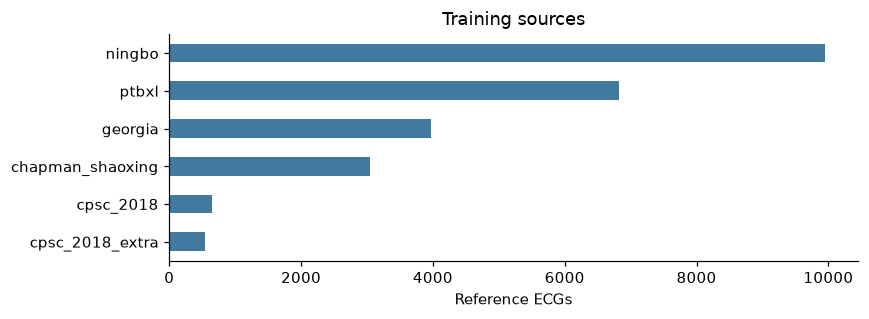

In [3]:
counts = result['counts']
display(pd.DataFrame([
    {'role': 'Reference training', 'records': counts['training'],
     'normal annotations': counts['training_normals'],
     'multiple abnormal groups': counts['training_multiple_groups']},
    {'role': 'SPH evaluation', 'records': counts['query'],
     'normal annotations': counts['query_normals'],
     'multiple abnormal groups': counts['query_multiple_groups']},
]).set_index('role'))
print('SPH evaluation patients:', counts['query_patients'])
support_counts = pd.DataFrame({'positive reference ECGs': counts['training_positive']})
support_counts['SPH positive ECGs'] = [
    result['metrics']['whole']['groups'][g]['positives'] for g in support_counts.index
]
display(support_counts)
source_counts = pd.Series(counts['training_sources']).sort_values()
source_counts.plot.barh(figsize=(8, 3), color='#427a9f', xlabel='Reference ECGs', title='Training sources')
plt.tight_layout()
plt.show()

### 3. Integrity before new scores

Every directly used input is checked against predecessor receipt hashes. The saved HEADS-01
SPH prediction metrics are recomputed exactly, without refitting its models. Separately, averaging
the 40 float16 cached tokens must reproduce the saved float32 pooled vector to relative L2 error
at most 0.001. That second test qualifies pooling semantics at cache precision; it does not imply
bit-identical embeddings. A mismatch stops the experiment rather than silently dropping records.
The first attempt stopped before scoring because it could not parse decimal membership strings.
The committed v2 execution correction validates those strings as exact numeric zero/one values;
the scientific comparison and cohort identities are unchanged and the failed attempt is preserved.

Earlier local visual/native reference-matching studies did not establish improvement over their
strongest controls. KEY-01 does not change those outcomes. Experiments 024/024b motivated the
prototype comparator; their unavailable original outputs were not claimed as reproduced.

In [4]:
print('Exact predecessor replay:', result['integrity']['predecessor'])
display(pd.DataFrame(result['integrity']['pooling']).T)
print('Verified directly used inputs:', len(result['input_sha256']))
display(pd.DataFrame([result['profile']]))

Exact predecessor replay: {'exact': True, 'models': 13, 'metric_fields': 169}


,rows,max_relative_l2_error,tolerance
train,25000.0,0.000064,0.001
query,10434.0,0.000202,0.001


Verified directly used inputs: 15


,records,seconds,forecast_seconds,ceiling_seconds,admitted,safety_factor,gpu_used
0,128,0.529638,219.928006,1800,True,1.5,False


### 4. The keys and similarity score

Fit a StandardScaler on full-record **training** embeddings only. Apply that same scaler to
whole vectors and window means, then normalize each vector to unit length. Each reference ECG
has equal weight within a key. The positive key for group $c$ and its score are:

$$k_c^+ = \operatorname{unit}\left(\frac{1}{N_c}\sum_{i:y_{ic}=1}z_i\right),
\qquad s_c(z)=z^\top k_c^+ - z^\top k_c^0.$$

$k_c^0$ is the normal-reference key. Other abnormal groups are not treated as normal support.
Multiple-label ECGs contribute to every applicable positive key. Similarity margins are uncalibrated
scores, not disease probabilities. A whole-record key is one mean direction; variation within a
group and coexisting annotations can make that direction an incomplete description.

For selected-region keys, positive references choose their largest initial margin and normal
references choose their smallest margin. These selected vectors are averaged into new keys
**once**. Query labels never enter region selection. Selecting regions from record-level labels
is weak supervision, not a regional annotation of where a finding occurs.

In [5]:
# Verify the geometric meaning of the saved keys using only local private artifacts.
key_norms = []
for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
    for kind in ['positive', 'normal']:
        values = private[f'{arm}_{kind}']
        np.testing.assert_allclose(np.linalg.norm(values, axis=1), 1.0, atol=1e-12)
        key_norms.append({'arm': names[arm], 'key': kind,
                          'number': len(values), 'dimensions': values.shape[1]})
display(pd.DataFrame(key_norms))

,arm,key,number,dimensions
0,Whole-record keys,positive,4,1024
1,Whole-record keys,normal,4,1024
2,Selected-region keys,positive,4,1024
3,Selected-region keys,normal,4,1024
4,Fixed 1-second region keys,positive,4,1024
5,Fixed 1-second region keys,normal,4,1024


### 5. Candidate regions and controls

xECG uses 25 samples per patch at 100 Hz: 40 contextual tokens across a ten-second ECG.
Variable proposals include every stride-one span of 2, 4 or 8 tokens: 109 windows of nominal
length 0.5, 1 or 2 seconds. The fixed-window control uses ten nonoverlapping one-second windows.
Ties choose the first candidate in length/start order. No window length is tuned on SPH.

The tokens contain context from the encoder. Pooling tokens belonging to a span is not the same
as encoding that cropped waveform alone. These indices do not establish a clinical boundary.

The five arms isolate the whole-record baseline, region search using unchanged keys, reference
region selection, a simpler fixed-window selection control, and a cyclic permutation of group keys.
Each query's group score is the maximum margin across its candidate windows. No single winning
condition is forced on a recording: the four scores can all be high or low.

,proposal,candidates per ECG,lengths in seconds
0,Variable,109,"0.5, 1, 2"
1,Fixed,10,1


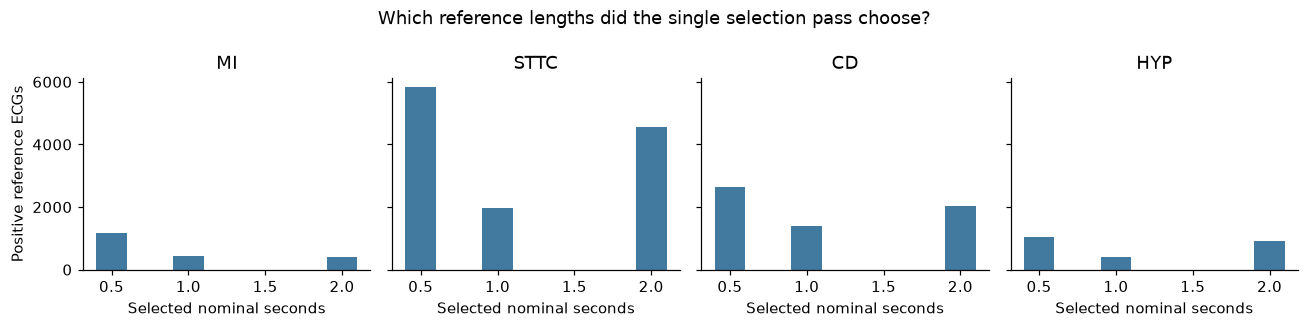

In [6]:
from ecg_experiment.condition_keys import spans

display(pd.DataFrame([
    {'proposal': 'Variable', 'candidates per ECG': len(spans()), 'lengths in seconds': '0.5, 1, 2'},
    {'proposal': 'Fixed', 'candidates per ECG': len(spans(True)), 'lengths in seconds': '1'},
]))
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, group in zip(axes, groups):
    hist = result['selections']['window_selected_keys']['support_positive'][group]['lengths']
    ax.bar([float(k) * 0.25 for k in hist], list(hist.values()), width=0.2, color='#427a9f')
    ax.set(title=group, xlabel='Selected nominal seconds')
axes[0].set_ylabel('Positive reference ECGs')
fig.suptitle('Which reference lengths did the single selection pass choose?')
plt.tight_layout()
plt.show()

### 6. Primary prediction results

For each group, every other SPH evaluation ECG counts as a negative, including recordings with
other abnormal groups. This evaluates whether the key distinguishes the requested group rather
than only separating abnormal ECGs from normal ones. Missing or imperfect annotations limit that
interpretation. AUROC measures ranking, with 0.5 indicating chance ranking; average precision (AP)
also depends on the group's prevalence. Neither metric sets a clinical referral threshold.

The primary endpoint is the unweighted mean of the four AUROCs. The frozen contrast is selected
region keys minus whole-record keys. Its interval uses 2,000 paired whole-patient bootstrap draws,
seed 20261103. The same patients are sampled for all groups and both arms. It holds the support
cohort, learned keys and pretrained encoder fixed.

,macro AUROC,macro AP
arm,,
Whole-record keys,0.8961,0.4178
"Region search, whole-record keys",0.8873,0.4114
Selected-region keys,0.7740,0.2593
Fixed 1-second region keys,0.8193,0.2948
Permuted condition keys,0.7025,0.1561


,difference,ci_low,ci_high,draws,skipped_draws,seed
0,-0.122072,-0.133550,-0.111008,2000,0,20261103


Frozen decision gates: {'gain_at_least_0.01': False, 'lower_95_above_zero': False, 'at_least_fixed_window_point': False, 'advance': False, 'pipeline_promoted': False}


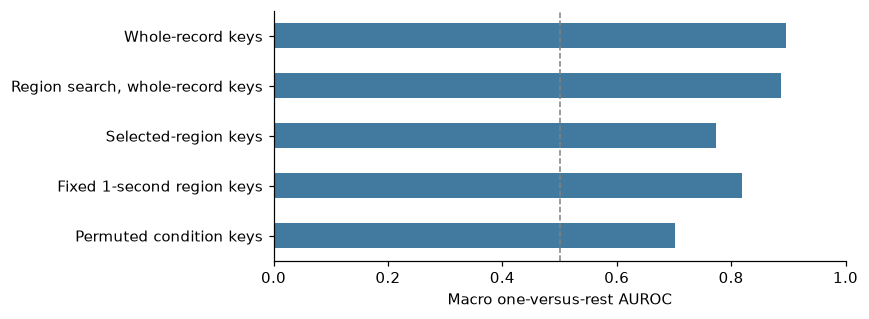

In [7]:
summary = pd.DataFrame([
    {'arm': names[arm], 'macro AUROC': result['metrics'][arm]['macro_auroc'],
     'macro AP': result['metrics'][arm]['macro_average_precision']}
    for arm in arms
]).set_index('arm')
display(summary.style.format('{:.4f}'))
primary = result['primary']
display(pd.DataFrame([primary]).style.format(precision=6))
print('Frozen decision gates:', result['decision'])
fig, ax = plt.subplots(figsize=(8, 3))
summary['macro AUROC'].iloc[::-1].plot.barh(ax=ax, color='#427a9f')
ax.set(xlim=(0, 1), xlabel='Macro one-versus-rest AUROC', ylabel='')
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

arm,Fixed 1-second region keys,Permuted condition keys,"Region search, whole-record keys",Selected-region keys,Whole-record keys
group,,,,,
CD,0.7845,0.6681,0.8271,0.7362,0.8409
HYP,0.8169,0.6616,0.8931,0.7806,0.8956
MI,0.8277,0.8061,0.9111,0.7516,0.9245
STTC,0.8481,0.6743,0.9178,0.8278,0.9234


arm,Fixed 1-second region keys,Permuted condition keys,"Region search, whole-record keys",Selected-region keys,Whole-record keys
group,,,,,
CD,0.3640,0.1794,0.4289,0.2860,0.4561
HYP,0.0928,0.0222,0.2225,0.0743,0.2047
MI,0.0654,0.0490,0.2032,0.0471,0.2149
STTC,0.6570,0.3739,0.7912,0.6298,0.7956


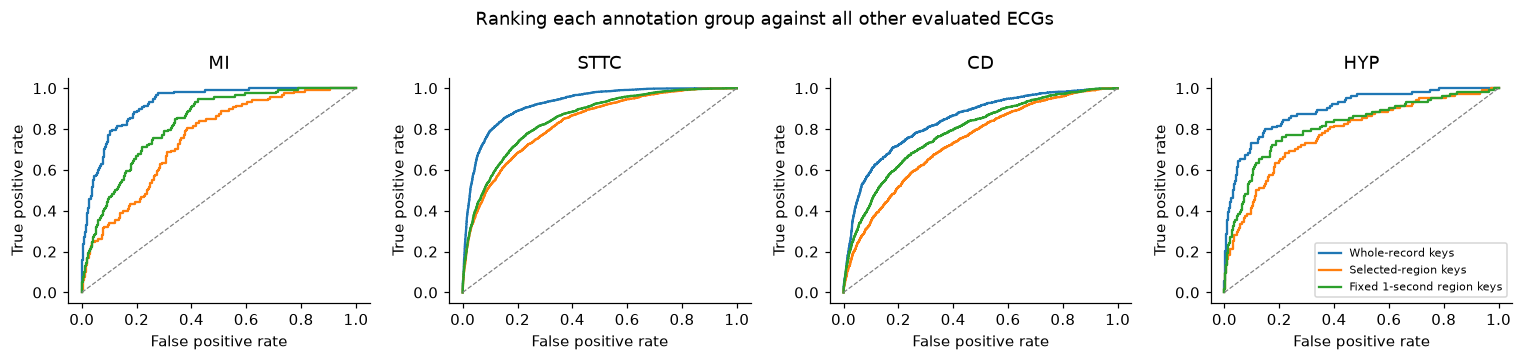

In [8]:
per_group = pd.DataFrame([
    {'group': group, 'arm': names[arm], **result['metrics'][arm]['groups'][group]}
    for group in groups for arm in arms
])
display(per_group.pivot(index='group', columns='arm', values='auroc').style.format('{:.4f}'))
display(per_group.pivot(index='group', columns='arm', values='average_precision').style.format('{:.4f}'))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for c, (ax, group) in enumerate(zip(axes, groups)):
    y = private['query_flags'][:, c]
    for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
        fpr, tpr, _ = roc_curve(y, private[f'score_{arm}'][:, c])
        ax.plot(fpr, tpr, label=names[arm])
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=0.8)
    ax.set(title=group, xlabel='False positive rate', ylabel='True positive rate')
axes[-1].legend(loc='lower right', fontsize=7)
fig.suptitle('Ranking each annotation group against all other evaluated ECGs')
plt.tight_layout()
plt.show()

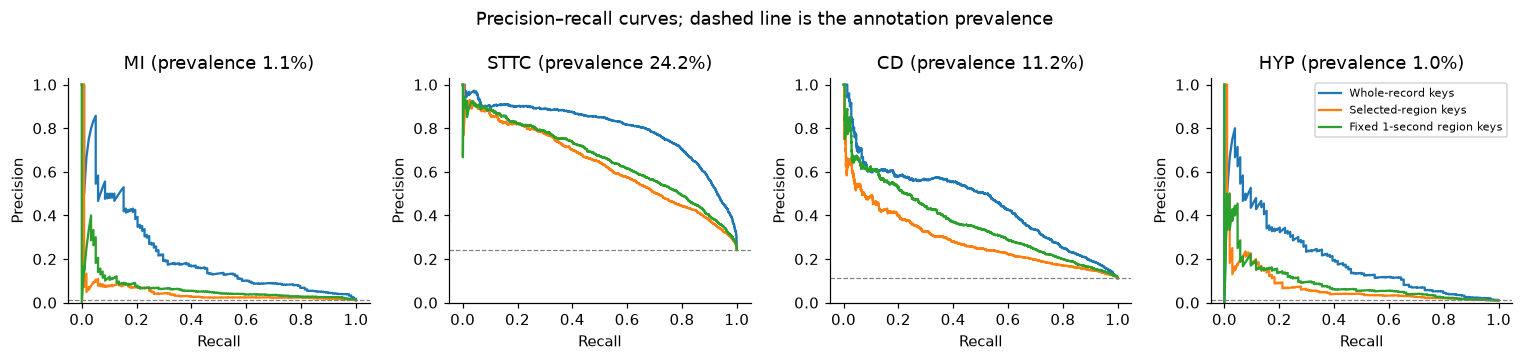

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for c, (ax, group) in enumerate(zip(axes, groups)):
    y = private['query_flags'][:, c]
    for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
        precision, recall, _ = precision_recall_curve(y, private[f'score_{arm}'][:, c])
        ax.plot(recall, precision, label=names[arm])
    ax.axhline(y.mean(), linestyle='--', color='gray', linewidth=0.8)
    ax.set(title=f'{group} (prevalence {y.mean():.1%})', xlabel='Recall', ylabel='Precision', ylim=(0, 1.03))
axes[-1].legend(fontsize=7)
fig.suptitle('Precision–recall curves; dashed line is the annotation prevalence')
plt.tight_layout()
plt.show()

### 7. Why the negative comparison matters

Condition-versus-normal discrimination is an easier, different task: other abnormalities are
removed from the negatives. The next table shows both definitions without substituting the
easier one for the primary endpoint. If performance is higher against normals, part of the
representation may reflect general abnormality rather than a specific annotation group.

In [10]:
negative_comparison = pd.DataFrame([
    {'group': group, 'comparison': task, 'AUROC': values[arm]['groups'][group]['auroc'],
     'AP': values[arm]['groups'][group]['average_precision']}
    for group in groups
    for task, values in [('All other ECGs', result['metrics']),
                         ('Normal ECGs only', result['condition_vs_normal'])]
    for arm in ['window_selected_keys']
])
comparison_table = negative_comparison.pivot(index='group', columns='comparison', values=['AUROC', 'AP'])
display(comparison_table.style.format('{:.4f}'))

### 8. Do the keys point in similar directions?

Cosine similarity between positive keys describes embedding geometry. High similarity can reflect
shared morphology, coexisting annotations, general abnormality or source effects. It is not a
measure of clinical equivalence or the probability that two diagnoses occur together.

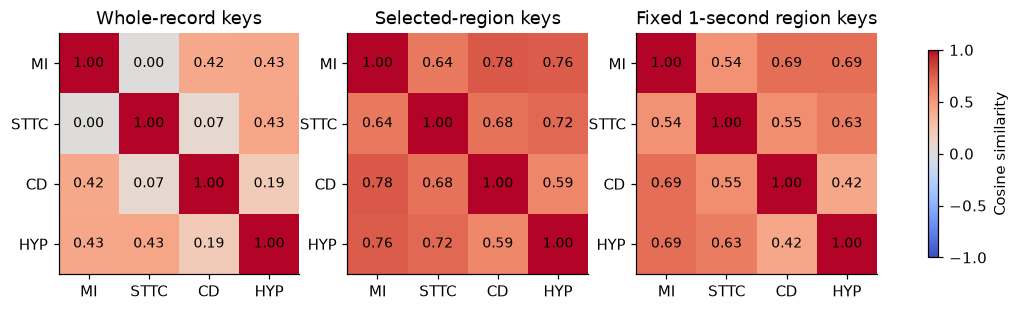

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, arm in zip(axes, ['whole', 'window_selected_keys', 'fixed_selected_keys']):
    values = np.asarray(result['positive_key_cosines'][arm])
    im = ax.imshow(values, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=range(4), yticks=range(4), xticklabels=groups, yticklabels=groups, title=names[arm])
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{values[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=list(axes), shrink=0.7, label='Cosine similarity')
plt.show()

### 9. Descriptive clusters: fitting without condition labels

PCA is fitted on standardized, unit whole-record **training** embeddings (16 components).
K-means then partitions those training coordinates into five clusters, with ten initializations
and seed 20261103. SPH is projected and assigned to the frozen centers. Annotation memberships
do not enter PCA or k-means; they are used afterward to describe each cluster.

Five is a prespecified number of clusters, not a finding that five types of disease exist.
Cluster numbers have no clinical names. A cluster can contain normals, several conditions and
unannotated variation. We compare adjusted mutual information (AMI) with source family and the
exact combination of the four annotations. AMI is descriptive, adjusts for chance and depends on
the factors being compared; it does not prove removal of hospital effects or clinical validity.

First two PCA components explain 17.0% of training variance.
All sixteen explain 58.9%.


,Training cluster AMI
source_family,0.041888
annotation_combination,0.159981


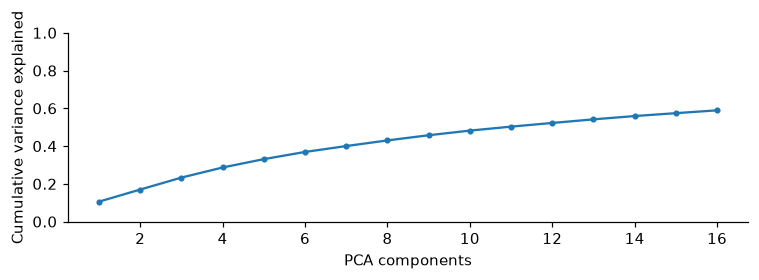

In [12]:
cluster = result['clusters']
variance = np.asarray(cluster['pca_explained_variance_ratio'])
print(f'First two PCA components explain {variance[:2].sum():.1%} of training variance.')
print(f'All sixteen explain {variance.sum():.1%}.')
display(pd.Series(cluster['training_ami'], name='Training cluster AMI').to_frame())
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(np.arange(1, 17), np.cumsum(variance), marker='o', markersize=3)
ax.set(xlabel='PCA components', ylabel='Cumulative variance explained', ylim=(0, 1))
plt.tight_layout()
plt.show()

,records,normal,MI,STTC,CD,HYP
Training cluster,,,,,,
0,4048,0,239,3349,1350,373
1,5030,2928,457,1043,638,377
2,5218,238,638,3466,2047,706
3,5862,3914,164,1200,523,304
4,4842,313,543,3298,1491,616


,records,normal,MI,STTC,CD,HYP
SPH cluster,,,,,,
0,210,0,6,179,48,23
1,4091,3026,39,639,415,14
2,1026,58,45,750,291,37
3,4153,3442,7,477,233,17
4,954,324,21,476,179,13


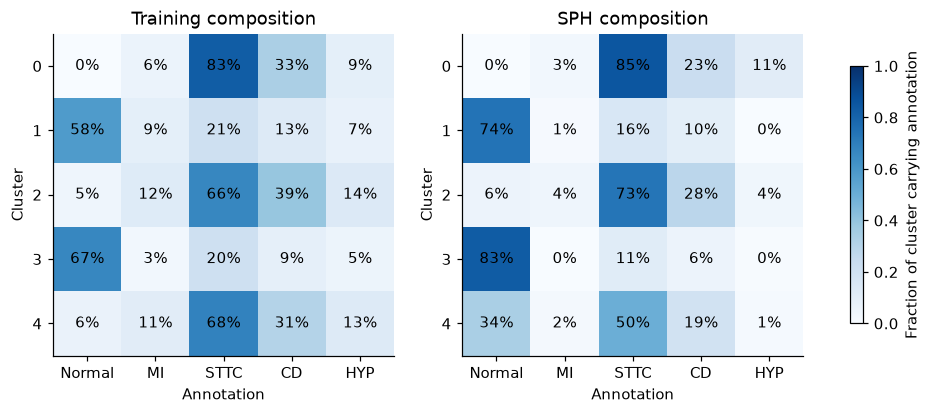

Group memberships overlap, so the annotation fractions need not add to 100%.


In [13]:
train_clusters = pd.DataFrame(cluster['training']).set_index('cluster')
query_clusters = pd.DataFrame(cluster['sph']).set_index('cluster')
display(train_clusters.rename_axis('Training cluster'))
display(query_clusters.rename_axis('SPH cluster'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, table, title in zip(axes, [train_clusters, query_clusters],
                           ['Training composition', 'SPH composition']):
    prevalence = table[['normal', *groups]].div(table['records'], axis=0).fillna(0)
    im = ax.imshow(prevalence, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(5), yticks=range(5), xticklabels=['Normal', *groups],
           yticklabels=range(5), xlabel='Annotation', ylabel='Cluster', title=title)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{prevalence.iloc[i, j]:.0%}', ha='center', va='center')
fig.colorbar(im, ax=list(axes), shrink=0.8, label='Fraction of cluster carrying annotation')
plt.show()
print('Group memberships overlap, so the annotation fractions need not add to 100%.')

,chapman_ningbo,cpsc,georgia,ptbxl
cluster,,,,
0,3338,57,204,449
1,1998,290,719,2023
2,2423,281,1242,1272
3,2599,231,839,2193
4,2644,337,970,891


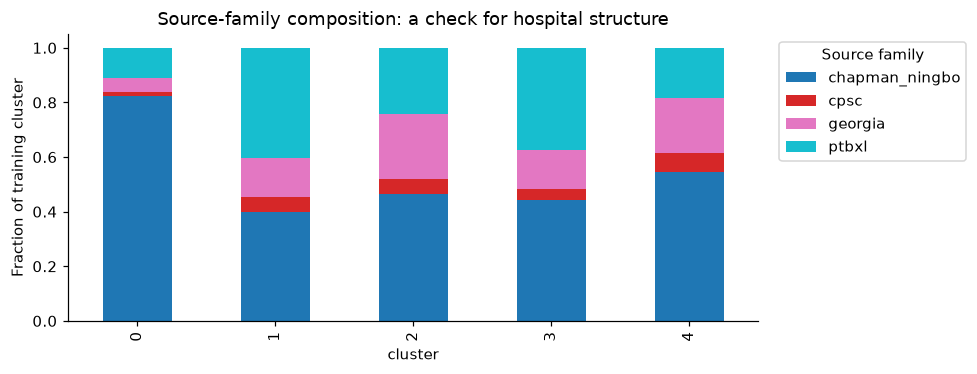

In [14]:
sources = pd.DataFrame(cluster['training_source_counts']).set_index('cluster')
display(sources)
sources.div(sources.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(9, 3.5), colormap='tab10')
plt.ylabel('Fraction of training cluster')
plt.title('Source-family composition: a check for hospital structure')
plt.legend(title='Source family', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 10. A two-dimensional view of SPH embeddings

The following charts are aggregated density grids, not individual patient scatter plots. All use
the same PCA axes fitted on training data. Each panel includes records carrying its annotation;
multiple-label records appear in more than one panel. For visual comparison, each panel's density
is normalized by its own record count, with a shared color scale. The grid bounds come from the
0.5th–99.5th training percentiles, and out-of-grid counts are reported. Two-dimensional overlap
does not establish overlap in all sixteen clustering dimensions, and apparent separation does
not establish useful classification accuracy.

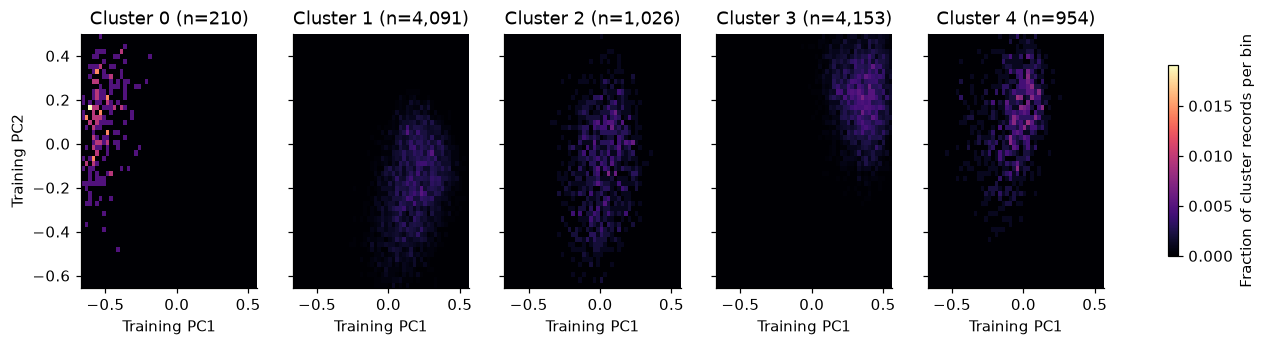

In [15]:
# Show the frozen cluster assignments on the same training-fitted PCA plane.
edges = [np.asarray(e) for e in cluster['grid_edges']]
coordinates = private['query_pca']
assigned = private['query_cluster']
cluster_grids = []
for k in range(5):
    keep = assigned == k
    grid, _, _ = np.histogram2d(coordinates[keep, 0], coordinates[keep, 1], bins=edges)
    cluster_grids.append(grid.T / keep.sum())
vmax = max(g.max() for g in cluster_grids)
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for k, (ax, grid) in enumerate(zip(axes, cluster_grids)):
    im = ax.pcolormesh(*edges, grid, vmin=0, vmax=vmax, cmap='magma', shading='auto')
    ax.set(title=f'Cluster {k} (n={(assigned == k).sum():,})', xlabel='Training PC1')
axes[0].set_ylabel('Training PC2')
fig.colorbar(im, ax=list(axes), shrink=0.75, label='Fraction of cluster records per bin')
plt.show()

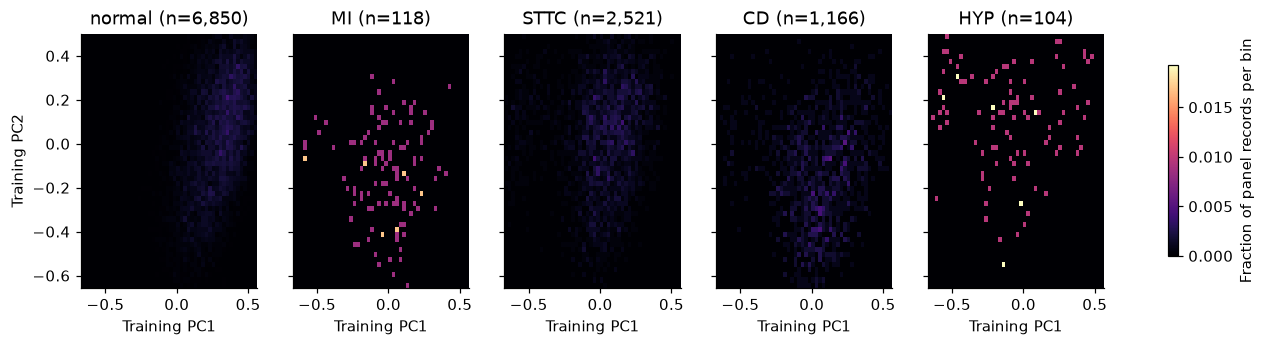

,records,outside_grid
normal,6850,125
MI,118,1
STTC,2521,26
CD,1166,10
HYP,104,1


In [16]:
panel_names = ['normal', *groups]
grids = cluster['sph_pca_grids']
xedges, yedges = [np.asarray(e) for e in cluster['grid_edges']]
densities = {g: np.asarray(grids[g]['counts']).T / grids[g]['records'] for g in panel_names}
vmax = max(a.max() for a in densities.values())
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for ax, group in zip(axes, panel_names):
    im = ax.pcolormesh(xedges, yedges, densities[group], cmap='magma', vmin=0, vmax=vmax, shading='auto')
    ax.set(title=f'{group} (n={grids[group]["records"]:,})', xlabel='Training PC1')
axes[0].set_ylabel('Training PC2')
fig.colorbar(im, ax=list(axes), shrink=0.75, label='Fraction of panel records per bin')
plt.show()
display(pd.DataFrame({g: {k: v for k, v in grids[g].items() if k != 'counts'} for g in panel_names}).T)

### 11. Arithmetic checks on the saved result

These checks reload the local private scores and recompute every per-group AUROC and AP,
including the condition-versus-normal task. They also check key geometry, region histograms
and cluster accounting. They do not refit keys or choose a new analysis after seeing results.
The saved patient-bootstrap interval and decision remain the prospectively specified comparison.

In [17]:
checks = 0
flags = private['query_flags']
for arm in arms:
    scores = private[f'score_{arm}']
    for c, group in enumerate(groups):
        for normal_only, container in [(False, result['metrics']), (True, result['condition_vs_normal'])]:
            keep = (flags[:, c] == 1) | ~flags.any(axis=1) if normal_only else np.ones(len(flags), bool)
            expected = container[arm]['groups'][group]
            assert roc_auc_score(flags[keep, c], scores[keep, c]) == expected['auroc']
            assert average_precision_score(flags[keep, c], scores[keep, c]) == expected['average_precision']
            checks += 2
for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
    key = private[f'{arm}_positive']
    np.testing.assert_array_equal(key @ key.T, np.asarray(result['positive_key_cosines'][arm]))
    checks += 1
assert sum(row['records'] for row in cluster['training']) == counts['training']
assert sum(row['records'] for row in cluster['sph']) == counts['query']
checks += 2
for arm in ['window_selected_keys', 'fixed_selected_keys']:
    for group in groups:
        selection = result['selections'][arm]['query_all'][group]
        assert sum(selection['starts']) == sum(selection['lengths'].values()) == counts['query']
        checks += 1
assert len(np.unique(private['query_patient'])) == counts['query_patients']
checks += 1
for prefix, rows in [('training', cluster['training']), ('query', cluster['sph'])]:
    local_flags = private['train_flags'] if prefix == 'training' else flags
    local_cluster = private[f'{prefix}_cluster']
    for row in rows:
        mask = local_cluster == row['cluster']
        assert int(mask.sum()) == row['records']
        assert int((~local_flags[mask].any(axis=1)).sum()) == row['normal']
        checks += 2
        for c, group in enumerate(groups):
            assert int(local_flags[mask, c].sum()) == row[group]
            checks += 1
print(f'{checks} saved-output arithmetic checks passed.')
verification = {
    'study': 'KEY-01', 'status': 'passed', 'checks': checks,
    'artifact_sha256': sha256_file(artifact_path), 'report_sha256': sha256_file(report_path),
    'refitted': False, 'raw_waveforms_read': False,
}

154 saved-output arithmetic checks passed.


### 12. What this experiment establishes

The executed result below describes the fixed contrast, not a search for the best-looking arm.
Advancement requires a macro-AUROC gain of at least 0.01, a 95% lower bound above zero, and
a candidate point estimate at least as high as the fixed-window control. Cluster composition
and easier condition-versus-normal comparisons do not replace a failed primary gate.

This experiment measures recognition of four existing annotation groups on reused hospital
development ECGs. It does not test absent-reference diseases, physiological segmentation,
clinical diagnosis, university-student referral performance or an untouched final test. The interval
does not quantify uncertainty from resampling reference patients or retraining the encoder.
Project recommendations and follow-up priorities are recorded in the separate results report.

The selected-region versus whole-record macro-AUROC difference was
**-0.1221**, with a paired 95% interval
**[-0.1336, -0.1110]**. The selected-region candidate
did not pass all three frozen advancement gates. This is the prespecified result even when a
secondary control or an individual annotation group has a more favorable point estimate.

Per-group changes are descriptive and have no separate confirmatory intervals:

- MI: selected-region AUROC 0.7516, whole-record 0.9245; difference -0.1729.
- STTC: selected-region AUROC 0.8278, whole-record 0.9234; difference -0.0956.
- CD: selected-region AUROC 0.7362, whole-record 0.8409; difference -0.1047.
- HYP: selected-region AUROC 0.7806, whole-record 0.8956; difference -0.1151.

The cluster composition tables give these descriptive concentrations:

- MI is most concentrated in cluster 2: 4.4% of its 1,026 ECGs carry the annotation, against 1.1% across all SPH evaluation ECGs.
- STTC is most concentrated in cluster 0: 85.2% of its 210 ECGs carry the annotation, against 24.2% across all SPH evaluation ECGs.
- CD is most concentrated in cluster 2: 28.4% of its 1,026 ECGs carry the annotation, against 11.2% across all SPH evaluation ECGs.
- HYP is most concentrated in cluster 0: 11.0% of its 210 ECGs carry the annotation, against 1.0% across all SPH evaluation ECGs.

These are annotation enrichments, not cluster diagnoses. The same cluster may be most enriched for several groups, and a group's ECGs may span multiple clusters.

In [18]:
print(f'Selected-region macro AUROC: {summary.loc[names["window_selected_keys"], "macro AUROC"]:.6f}')
print(f'Whole-record macro AUROC: {summary.loc[names["whole"], "macro AUROC"]:.6f}')
print(f'Difference: {primary["difference"]:+.6f}; '
      f'95% interval [{primary["ci_low"]:+.6f}, {primary["ci_high"]:+.6f}]')
print('All frozen advancement gates passed:', result['decision']['advance'])
print('SAM executed:', result['sam_executed'])
print('Previously unsupported diseases evaluated:', result['unseen_disease_evaluated'])

Selected-region macro AUROC: 0.774030
Whole-record macro AUROC: 0.896102
Difference: -0.122072; 95% interval [-0.133550, -0.111008]
All frozen advancement gates passed: False
SAM executed: False
Previously unsupported diseases evaluated: False


### Reproduction and AI assistance

The full scientific run is `uv run --no-sync python -m scripts.experiments.run_condition_keys_v2`.
It requires the local, hash-bound caches and refuses to overwrite its output directory. The
notebook builder is `uv run --no-sync python -m scripts.reports.build_condition_keys_notebook`.
The notebook replays the completed outputs; it does not repeat encoder extraction or training.
See `docs/condition-keys-protocol-2026-11-03.md` and
`docs/condition-keys-results-2026-11-03.md` for the frozen design and results report.

OpenAI Codex assisted in developing the protocol, Python implementation, analysis and explanatory
text. Numerical results were computed locally from the project's existing artifacts. No external
model inference was used on ECG data in KEY-01. Private per-record arrays remain local; the
notebook displays aggregate tables, curves and density grids. The project authors remain
responsible for reviewing the interpretation and its clinical scope.

<a id="key02"></a>
## II. Longer sections and temporal agreement — KEY-02

KEY-02, 6 November 2026. This is a prospective successor to `ConditionKeys.ipynb`.
The question is whether longer sections recover information lost by the previous 0.5–2-second
reference selection. The four overlapping groups remain MI, STTC, CD and HYP ECG annotations.
They are proxies, not verified diagnoses. All numerical findings below come from executed outputs.

### What ECG-JEPA contributes to the idea

[ECG-JEPA, sections 3.1–3.3](https://arxiv.org/html/2410.08559v2) uses synchronized temporal
masking across leads and Cross-Pattern Attention: patches connect along the same lead and across
leads at the same time. This structural bias is motivated by ECG interpretation. The paper does
not establish that the model reasons like a cardiologist.

Our cached xECG tokens already combine leads. This study tests longer temporal context and
agreement across sections. It does not implement CroPA, masked latent prediction, or a JEPA
encoder comparison. The median-score control is our experimental heuristic, not a method from
that paper. A direct lead-aware experiment requires lead-indexed representations.

In [19]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
result = json.loads((ROOT / 'reports/long-section-keys-2026-11-06/aggregate.json').read_text())
private = np.load(ROOT / 'outputs/long_section_keys_20261106/artifacts.npz', allow_pickle=False)
assert result['status'] == 'completed'
groups = ['MI', 'STTC', 'CD', 'HYP']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Source commit:', result['git_commit'])
print('Reference ECGs:', result['counts']['training'])
print('SPH evaluation ECGs:', result['counts']['query'])
print('SPH patients:', result['counts']['query_patients'])
print('Integrity:', result['integrity'])

Source commit: 0acb4693e717f39f1f7dd4592ad4f2e9cc976752
Reference ECGs: 25000
SPH evaluation ECGs: 10434
SPH patients: 10116
Integrity: {'exact_metric_dictionaries': 10, 'primary_interval_exact': True, 'result_sha256': '8d8f5b92f065c2614f1fbf9c375232cb2cec2dda65344c0efc63ad72b47f5285', 'private_sha256': '0135113cbc65e1b1e73064c94422f74537c91aadd90a6473567726f183478619', 'whole_score_max_error': 0.0}


### Frozen design and data roles

The same 25,000 human-read-source reference ECGs and 10,434 SPH evaluation ECGs are used.
SPH never fits the scaler or keys. It is reused development data, not an untouched test.
The prior experiment's scores, metric dictionaries and primary patient interval reproduce exactly.
No closed Challenge/EchoNext test, new annotation, raw waveform or GPU is used.

Every 250 ms xECG token contains encoder context, so a span is not an independently encoded
waveform crop. Longer sections comprise 10, 20 or 30 tokens (2.5, 5 or 7.5 seconds).
All stride-one candidates are included: respectively 31, 21 and 11 windows per ECG.

Each arm starts from the same whole-record keys, chooses the highest-margin reference region
for positives and the lowest-margin region for normals, and averages these unit vectors once.
A query is scored by its maximum positive-minus-normal cosine margin. Two five-second controls
keep the whole-record keys and use either the maximum or the median window margin.
The median asks whether recurring evidence helps. Scores are not probabilities.

Five-second selected keys are the primary candidate. Advancement requires a macro-AUROC gain
of at least 0.01 over short selected keys, a positive lower 95% bound, and a point no more than
0.01 below whole-record keys. The final criterion is a descriptive guard, not noninferiority.
Other lengths cannot replace the primary candidate after seeing the results.

,macro AUROC,macro AP
arm,,
whole,0.896102,0.417818
short_selected,0.774030,0.259330
selected_2.5s,0.856926,0.344356
selected_5s,0.879836,0.384924
whole_keys_5s_max,0.895460,0.419443
whole_keys_5s_median,0.894789,0.417331
selected_7.5s,0.889927,0.406271


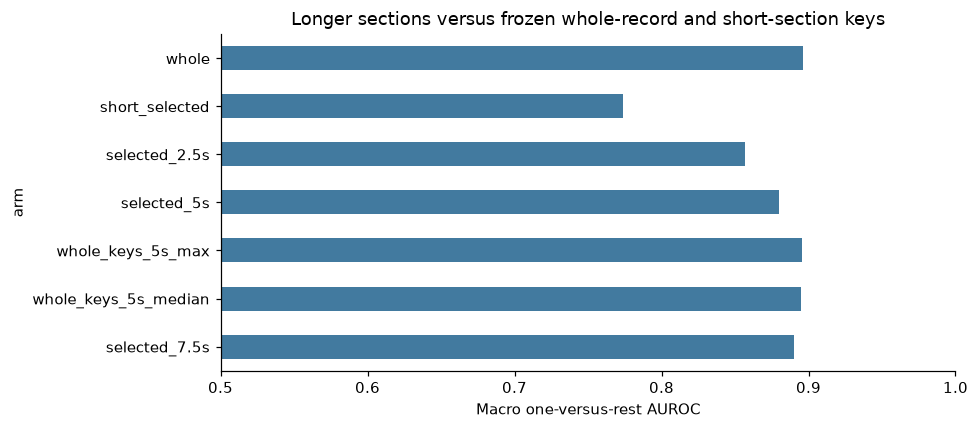

In [20]:
summary = pd.DataFrame({name: {
    'macro AUROC': value['macro_auroc'],
    'macro AP': value['macro_average_precision']}
    for name, value in result['metrics'].items()}).T
summary.index.name = 'arm'
display(summary.style.format('{:.6f}'))
summary['macro AUROC'].iloc[::-1].plot.barh(figsize=(9, 4), color='#427a9f')
plt.xlim(0.5, 1)
plt.xlabel('Macro one-versus-rest AUROC')
plt.title('Longer sections versus frozen whole-record and short-section keys')
plt.tight_layout()
plt.show()

### Primary contrast and practical guard

AUROC is computed separately for each group against all other evaluated ECGs, including other
abnormalities, then averaged across the four groups. The paired bootstrap resamples whole
patients 2,000 times with seed 20261103 and the same patients for both arms. Intervals condition
on one fixed reference cohort and encoder. The whole-record contrast is descriptive.

In [21]:
display(pd.DataFrame({
    '5s minus short selected': result['primary'],
    '5s minus whole record': result['versus_whole'],
}).T)
print('Decision:', result['decision'])
print('All advancement criteria passed:', result['decision']['advance'])

,difference,ci_low,ci_high,draws,skipped_draws,seed
5s minus short selected,0.105805,0.096213,0.115893,2000.0,0.0,20261103.0
5s minus whole record,-0.016266,-0.019793,-0.013137,2000.0,0.0,20261103.0


Decision: {'gain_at_least_0.01': True, 'lower_95_above_zero': True, 'within_0.01_of_whole_point': False, 'advance': False}
All advancement criteria passed: False


### Differences across annotation groups

A high average can hide poor recognition of a particular group. These per-group results are
descriptive; no separate confirmatory claims are made. Labels overlap, so this is not a forced
choice among four diseases. AP is prevalence-dependent, particularly for the rarer MI/HYP groups.

,whole,short_selected,selected_2.5s,selected_5s,whole_keys_5s_max,whole_keys_5s_median,selected_7.5s
MI,0.9245,0.7516,0.8776,0.9053,0.9236,0.9240,0.9169
STTC,0.9234,0.8278,0.8808,0.9058,0.9229,0.9226,0.9168
CD,0.8409,0.7362,0.8229,0.8401,0.8415,0.8393,0.8428
HYP,0.8956,0.7806,0.8465,0.8681,0.8938,0.8933,0.8831


,whole,short_selected,selected_2.5s,selected_5s,whole_keys_5s_max,whole_keys_5s_median,selected_7.5s
MI,0.2149,0.0471,0.1152,0.1582,0.2152,0.2190,0.1893
STTC,0.7956,0.6298,0.7170,0.7610,0.7957,0.7937,0.7820
CD,0.4561,0.2860,0.4257,0.4573,0.4519,0.4524,0.4617
HYP,0.2047,0.0743,0.1196,0.1633,0.2150,0.2042,0.1921


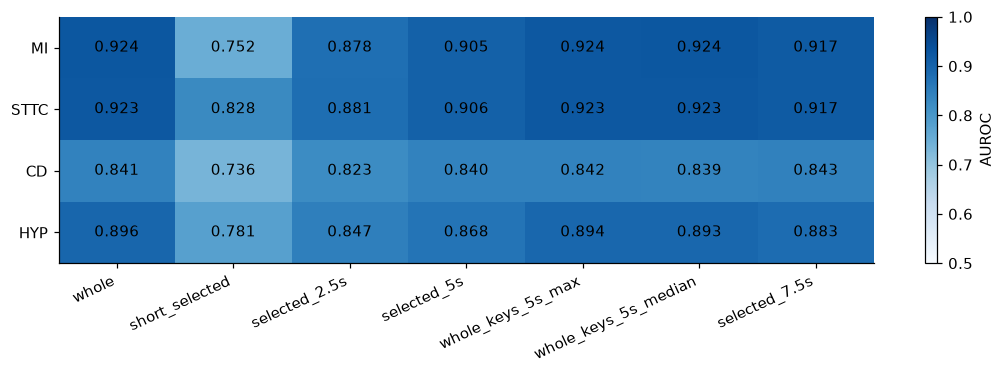

In [22]:
auroc = pd.DataFrame({arm: {g: v['groups'][g]['auroc'] for g in groups}
                      for arm, v in result['metrics'].items()})
ap = pd.DataFrame({arm: {g: v['groups'][g]['average_precision'] for g in groups}
                   for arm, v in result['metrics'].items()})
display(auroc.style.format('{:.4f}'))
display(ap.style.format('{:.4f}'))
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(auroc.to_numpy(), vmin=0.5, vmax=1, cmap='Blues', aspect='auto')
ax.set(yticks=range(4), yticklabels=groups,
       xticks=range(len(auroc.columns)), xticklabels=auroc.columns)
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
for row in range(4):
    for col in range(len(auroc.columns)):
        ax.text(col, row, f'{auroc.iloc[row, col]:.3f}', ha='center', va='center')
fig.colorbar(im, ax=ax, label='AUROC')
plt.tight_layout()
plt.show()

### Does repeated evidence help?

The maximum and median five-second controls share identical whole-record keys and candidate
windows. Their comparison isolates this query aggregation choice. It does not isolate CroPA,
lead agreement or clinician reasoning. Stronger performance with longer windows can reflect
retaining more context, fewer candidate windows, or reduced reference-selection extremes; this
experiment does not separate those mechanisms.

In [23]:
display(summary.loc[['whole', 'whole_keys_5s_max', 'whole_keys_5s_median']])
print('Median minus maximum macro AUROC:',
      summary.loc['whole_keys_5s_median', 'macro AUROC'] - summary.loc['whole_keys_5s_max', 'macro AUROC'])
normal = pd.Series({k: v['macro_auroc'] for k, v in result['condition_vs_normal'].items()})
display(pd.DataFrame({'against all others': summary['macro AUROC'], 'against normals only': normal}))

,macro AUROC,macro AP
arm,,
whole,0.896102,0.417818
whole_keys_5s_max,0.895460,0.419443
whole_keys_5s_median,0.894789,0.417331


Median minus maximum macro AUROC: -0.0006711673200965329


,against all others,against normals only
whole,0.896102,0.944959
short_selected,0.774030,0.825079
selected_2.5s,0.856926,0.908386
selected_5s,0.879836,0.929829
whole_keys_5s_max,0.895460,0.944242
whole_keys_5s_median,0.894789,0.943813
selected_7.5s,0.889927,0.939042


### Saved-output verification and interpretation

The following cells independently recompute all per-group AUROCs and average precisions from
saved scores. No model is refitted or selected. The prior notebook's clustering results remain
unchanged; this experiment does not refit or relabel those clusters.

In [24]:
checks = 0
flags = private['flags']
for arm in result['metrics']:
    scores = private['score_' + arm]
    for c, group in enumerate(groups):
        for normal_only, key in [(False, 'metrics'), (True, 'condition_vs_normal')]:
            keep = ((flags[:, c] == 1) | ~flags.any(axis=1)
                    if normal_only else np.ones(len(flags), dtype=bool))
            expected = result[key][arm]['groups'][group]
            assert roc_auc_score(flags[keep, c], scores[keep, c]) == expected['auroc']
            assert average_precision_score(flags[keep, c], scores[keep, c]) == expected['average_precision']
            checks += 2
print('Exact metric checks passed:', checks)
primary = result['primary']
print(f'Five seconds minus short sections: {primary["difference"]:+.6f}')
print(f'95% interval: [{primary["ci_low"]:+.6f}, {primary["ci_high"]:+.6f}]')
print('Advance longer-section keys:', result['decision']['advance'])
print('Actual JEPA/CroPA executed:', result['jepa_or_cropa_executed'])

Exact metric checks passed: 112
Five seconds minus short sections: +0.105805
95% interval: [+0.096213, +0.115893]
Advance longer-section keys: False
Actual JEPA/CroPA executed: False


### Scope and reproduction

Results concern existing ECG annotation groups on reused hospital development data. No unseen
disease identification, physiological delineation, clinical reasoning or student screening
performance is established. Project recommendations belong in the accompanying results report.

Run the scientific study in a fresh output location with
`python -m scripts.experiments.run_long_section_keys`; it requires original hash-bound local
caches and refuses overwrite. Rebuild this notebook with
`python -m scripts.reports.build_long_section_notebook` in the project environment.

OpenAI Codex assisted with the prospective design, implementation and explanation. All reported
numbers were executed locally; patient-level arrays remain local. The authors are responsible for
reviewing the scientific and clinical interpretation.

<a id="key03"></a>
## III. The ECG references behind the averages — KEY-03

KEY-03 · Training-reference audit · 6 November 2026

This notebook examines the ECGs actually averaged in KEY-01 and KEY-02. It covers reference
composition, annotation overlap, repeated patients, source effects, embedding geometry and region
selection. The companion local waveform notebook and PDF contain twenty prespecified review
panels. Individual waveform panels and record mappings remain in ignored local outputs.

A key averages **standardized, unit-normalized embedding vectors**, not raw ECG voltages.
Each reference record has equal weight. A nearest reference is an example selected by the model's
geometry, not a clinician-approved typical case. These groups are overlapping annotation proxies.

In [25]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
r = json.loads((ROOT / 'reports/reference-ecg-audit-2026-11-06/aggregate.json').read_text())
assert r['status'] == 'completed'
groups = ['MI', 'STTC', 'CD', 'HYP']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Study:', r['study'], '| Source:', r['git_commit'])
print('Saved predecessor metric dictionaries reproduced:', r['metric_dictionaries_reproduced'])
print('New evaluation scores:', r['new_evaluation_scores'])

Study: KEY-03 | Source: 438adfbce29a6f5aa279fe1edb577e80b15bf23d
Saved predecessor metric dictionaries reproduced: 24
New evaluation scores: False


### 1. Population and what is known about its labels

All 25,000 reference records are from permitted training roles. SPH contributes no references.
Source-level physician-reading processes and individual human-validation fields are different
kinds of evidence. A missing per-record validation field does not establish that a label came
from software. The counts below preserve that distinction.

Patient identity is known only where the source supplies it. Unknown identities are not converted
into a claimed number of unique people. Exact signal-hash duplicates are a narrow duplication
check: absence of equal hashes cannot exclude near-duplicates or repeated patients.

In [26]:
overall = r['overall']
display(pd.Series({k: v for k, v in overall.items() if not isinstance(v, dict)}, name='count').to_frame())
display(pd.Series(overall['label_evidence'], name='records').to_frame())
validation = pd.Series(overall['individual_human_validation'], name='records')
display(validation.rename(index={'': 'unavailable'}).to_frame())
review = pd.Series(overall['review_flags'], name='records')
display(review.rename(index={'': 'no recorded review flag'}).to_frame())

,count
records,25000
known_identity_records,6828
known_patients,6359
unknown_identity_records,18172
known_patient_extra_record_count,469
duplicate_canonical_records,0
duplicate_full_signal_records,0


,records
source_process_physician_label_secondary_validation_senior_adjudication,13002
record_human_validated,6828
human_overread_source_no_per_record_reader_count_proof,3974
human_read_source_no_per_record_reader_count_proof,1196


,records
unavailable,18172
True,6828


,records
no recorded review flag,24849
amplitude_over_10mv,148
strong_baseline_wander,3


### 2. Which sources contribute to each average?

The four positive pools overlap. Normal references are the shared negative pool under the frozen
binary definition; they are not newly certified clinically normal. The number of records from each
family is its literal contribution to the arithmetic average before normalization. The direction
of its contribution also depends on its vectors, examined later.

,ptbxl,cpsc,chapman_ningbo,georgia,total
MI,1626,290,122,3,2041
STTC,1789,418,7872,2277,12356
CD,1537,488,3025,999,6049
HYP,843,32,465,1036,2376
normal,3038,154,3400,801,7393


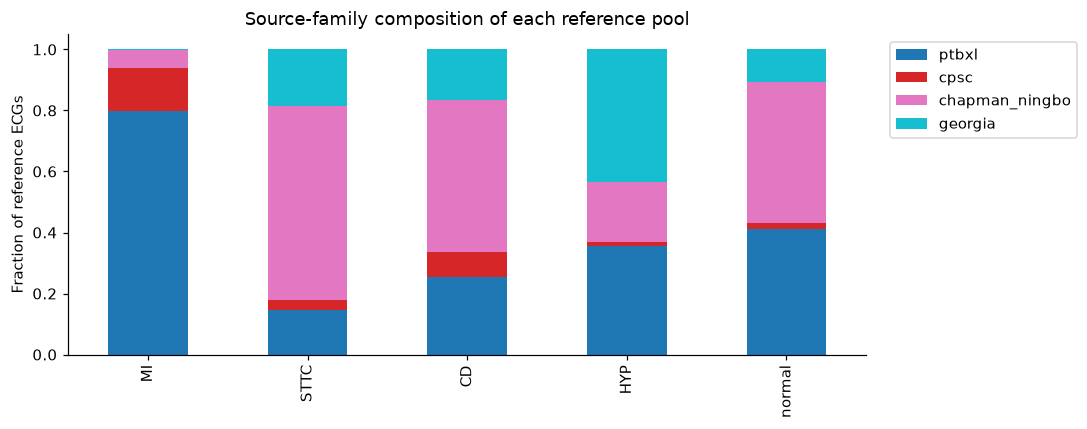

,records,known_patients,known_identity_records,unknown_identity_records,known_patient_extra_record_count
MI,2041,1501,1626,415,125
STTC,12356,1662,1789,10567,127
CD,6049,1428,1537,4512,109
HYP,2376,809,843,1533,34
normal,7393,2941,3038,4355,97


In [27]:

composition = pd.DataFrame({g: v['families'] for g, v in r['composition'].items()}).fillna(0).astype(int).T
composition['total'] = composition.sum(axis=1)
display(composition)
shares = composition.drop(columns='total').div(composition['total'], axis=0)
shares.plot.bar(stacked=True, figsize=(10, 4), colormap='tab10')
plt.ylabel('Fraction of reference ECGs')
plt.title('Source-family composition of each reference pool')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
identity = pd.DataFrame({g: {k: v[k] for k in ['records', 'known_patients',
    'known_identity_records', 'unknown_identity_records', 'known_patient_extra_record_count']}
    for g, v in r['composition'].items()}).T
display(identity)

### 3. Averaging mixed annotations

A vector can contribute to several condition keys. The diagonal below is each positive reference
count; off-diagonal entries count shared reference ECGs. Row-normalized values answer: among
references for this row's group, what fraction also carries the column's group? This is annotation
co-occurrence in the support cohort, not population disease prevalence or causation.

,MI,STTC,CD,HYP
MI,2041,686,663,285
STTC,686,12356,2265,1470
CD,663,2265,6049,583
HYP,285,1470,583,2376


,positive references,exclusive group references
MI,2041,812
STTC,12356,8578
CD,6049,3084
HYP,2376,593


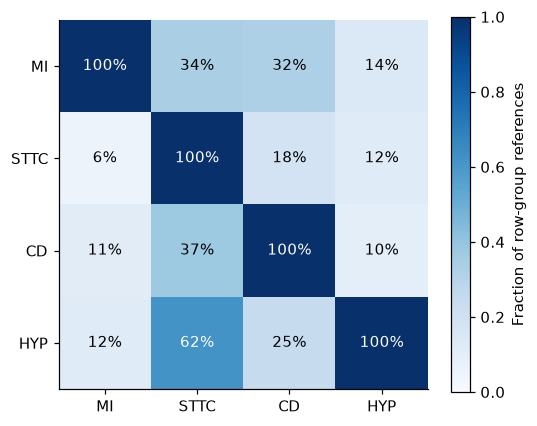

In [28]:
co = np.asarray(r['cooccurrence'])
assert np.array_equal(co, co.T)
display(pd.DataFrame(co, index=groups, columns=groups))
display(pd.DataFrame({'positive references': np.diag(co),
    'exclusive group references': [r['exclusive_counts'][g] for g in groups]}, index=groups))
conditional = co / np.diag(co)[:, None]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(conditional, vmin=0, vmax=1, cmap='Blues')
ax.set(xticks=range(4), yticks=range(4), xticklabels=groups, yticklabels=groups)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{conditional[i,j]:.0%}', ha='center', va='center',
                color='white' if conditional[i,j] > .6 else 'black')
fig.colorbar(im, ax=ax, label='Fraction of row-group references')
plt.tight_layout()
plt.show()

### 4. Reconstruction and compactness of the averages

Every positive and class-specific normal key is reconstructed directly from the original vectors
and saved window selections. Maximum coordinate error must be at most 1e-12, allowing only
summation-order differences. Selected references are not reselected in this audit.

Resultant length is the norm of the mean of unit vectors: values near one indicate stronger
alignment, while small values indicate cancellation. It describes support geometry; it is not
classification accuracy. Selecting regions to maximize training margins can create compact
reference directions without improving external ranking.

Key reconstruction errors: {'whole': 5.759281940243e-16, 'short': 0.0, 'fixed_1s': 0.0, '2.5s': 0.0, '5s': 0.0, '7.5s': 0.0}


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,0.4463,0.4202,0.4072,0.4322,0.4836,0.3859
normal_HYP,0.4284,0.4107,0.4019,0.4196,0.4513,0.3859
normal_MI,0.4397,0.4148,0.4034,0.4331,0.4973,0.3859
normal_STTC,0.4264,0.4122,0.4035,0.3965,0.4328,0.3859
positive_CD,0.2659,0.2418,0.2340,0.2895,0.3364,0.2295
positive_HYP,0.2407,0.2164,0.2013,0.2664,0.3056,0.1865
positive_MI,0.3024,0.2608,0.2428,0.3408,0.4193,0.2285
positive_STTC,0.1958,0.1749,0.1649,0.2170,0.2657,0.1552


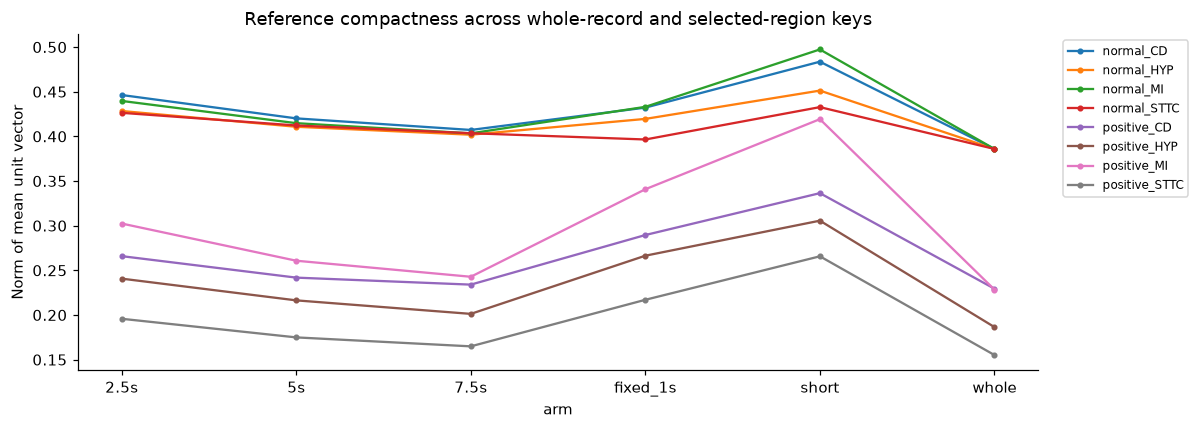

In [29]:
print('Key reconstruction errors:', {a: v['key_max_error'] for a, v in r['geometry'].items()})
geometry = pd.DataFrame([{'arm': a, 'key': g, **v}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()])
coherence = geometry.pivot(index='key', columns='arm', values='resultant_length')
display(coherence.style.format('{:.4f}'))
coherence.T.plot(figsize=(11, 4), marker='o', markersize=3)
plt.ylabel('Norm of mean unit vector')
plt.title('Reference compactness across whole-record and selected-region keys')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 5. How far do region keys rotate?

The angle below compares each key to its corresponding whole-record key. Normal-region keys
are class-specific after selection even though they use the same normal records. Consequently,
positive-key changes alone cannot explain a positive-minus-normal similarity score.

arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,26.31,18.13,13.43,33.29,35.42,0.00
normal_HYP,22.61,14.86,10.73,32.07,30.43,0.00
normal_MI,25.74,16.52,11.53,34.64,39.71,0.00
normal_STTC,19.98,14.11,10.81,24.10,23.62,0.00
positive_CD,23.31,13.17,9.56,33.07,38.96,0.00
positive_HYP,34.46,26.00,18.77,43.58,47.84,0.00
positive_MI,29.69,19.39,13.64,39.21,45.72,0.00
positive_STTC,29.16,20.87,16.00,39.12,44.67,0.00


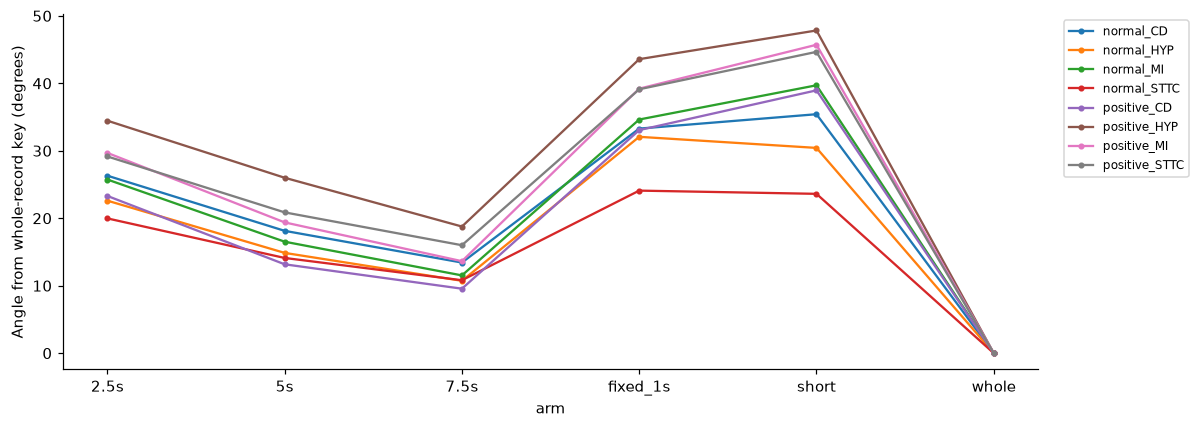

In [30]:
rotation = geometry.pivot(index='key', columns='arm', values='whole_key_rotation_degrees')
display(rotation.style.format('{:.2f}'))
rotation.T.plot(figsize=(11, 4), marker='o', markersize=3)
plt.ylabel('Angle from whole-record key (degrees)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 6. Source removal and known-patient weighting

Source-removed rotation is a geometric sensitivity check: subtract that family's vector sum and
measure the remaining key's angle from the original. It is not a retrained classifier or a hospital
transfer score. Large rotation can reflect both sample share and different recording/label patterns.

The equal-patient diagnostic gives equal weight to each known patient's mean representation;
unknown-patient records retain record weights. It cannot correct repeated patients that are not
identified by the data. No alternative weighting is promoted or evaluated on SPH.

In [31]:
removed = pd.DataFrame([{'arm': a, 'key': g, **v['source_removed_rotation_degrees']}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()]).set_index(['arm', 'key'])
display(removed.loc[['whole', 'short', '5s', '7.5s']].style.format('{:.2f}'))
patient_rotation = geometry.pivot(index='key', columns='arm', values='equal_patient_rotation_degrees')
display(patient_rotation.style.format('{:.3f}'))
exclusive = geometry.pivot(index='key', columns='arm', values='exclusive_vs_cooccurring_angle_degrees')
display(exclusive.dropna(how='all').style.format('{:.2f}', na_rep='not applicable'))

arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,0.361,0.407,0.428,0.340,0.300,0.458
normal_HYP,0.386,0.422,0.434,0.362,0.350,0.458
normal_MI,0.368,0.418,0.433,0.337,0.276,0.458
normal_STTC,0.373,0.417,0.430,0.364,0.353,0.458
positive_CD,0.809,0.916,0.941,0.653,0.560,0.953
positive_HYP,0.744,0.850,0.935,0.626,0.567,1.001
positive_MI,1.390,1.703,1.920,1.156,1.018,2.098
positive_STTC,0.602,0.706,0.775,0.475,0.394,0.840


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
positive_CD,41.94,47.77,50.23,34.12,28.08,51.71
positive_HYP,67.15,76.80,83.15,55.38,49.68,89.99
positive_MI,40.88,50.46,55.45,32.33,25.69,59.77
positive_STTC,50.19,58.33,62.82,41.42,34.44,66.62


### 7. Which ECGs are closest to a key?

The fifty highest reference-to-key cosines have the largest projections onto that key direction.
They still had the same averaging weight as other reference ECGs. Their source distribution can
be much more concentrated than the full support pool. This is why showing a handful of nearest
ECGs alone is insufficient to justify the average as representative.

In [32]:
nearest = pd.DataFrame([{'arm': a, 'key': g, **v['top50_sources']}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()]).fillna(0)
display(nearest.loc[nearest['arm'].isin(['whole', 'short', '5s', '7.5s'])].set_index(['arm', 'key']))
quantiles = pd.DataFrame([{'arm': a, 'key': g,
    **dict(zip(['min', 'p05', 'p25', 'median', 'p75', 'p95', 'max'], v['cosine_quantiles']))}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()])
display(quantiles.set_index(['arm', 'key']).round(3))

ptbxl  ningbo  cpsc_2018_extra  georgia  \
arm   key                                                      
whole positive_MI       45     2.0              2.0      1.0   
      positive_STTC      3    37.0              0.0      0.0   
      positive_CD       20    15.0              0.0      7.0   
      positive_HYP      13    11.0              2.0     24.0   
      normal_MI         19    25.0              0.0      0.0   
      normal_STTC       19    25.0              0.0      0.0   
      normal_CD         19    25.0              0.0      0.0   
      normal_HYP        19    25.0              0.0      0.0   
short positive_MI       49     0.0              0.0      1.0   
      positive_STTC      8    31.0              0.0      1.0   
      positive_CD       21    19.0              0.0      7.0   
      positive_HYP      30     1.0              0.0     19.0   
      normal_MI         15    27.0              0.0      2.0   
      normal_STTC       19    18.0              0.0      4.0   
      normal_CD         16    22.0              0.0      4.0   
      normal_HYP        14    26.0              0.0      1.0   
5s    positive_MI       48     1.0              0.0      1.0   
      positive_STTC      4    33.0              0.0      1.0   
      positive_CD       13    23.0              0.0      3.0   
      positive_HYP      17    10.0              1.0     22.0   
      normal_MI         16    27.0              0.0      0.0   
      normal_STTC       16    26.0              0.0      1.0   
      normal_CD         18    25.0              0.0      1.0   
      normal_HYP        15    27.0              0.0      0.0   
7.5s  positive_MI       47     1.0              1.0      1.0   
      positive_STTC      2    37.0              0.0      0.0   
      positive_CD       15    22.0              0.0      5.0   
      positive_HYP      13    10.0              2.0     25.0   
      normal_MI         19    26.0              0.0      0.0   
      normal_STTC       17    27.0              0.0      1.0   
      normal_CD         16    29.0              0.0      1.0   
      normal_HYP        18    27.0              0.0      1.0   

                     chapman_shaoxing  cpsc_2018  
arm   key                                         
whole positive_MI                 0.0        0.0  
      positive_STTC              10.0        0.0  
      positive_CD                 5.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   6.0        0.0  
      normal_STTC                 6.0        0.0  
      normal_CD                   6.0        0.0  
      normal_HYP                  6.0        0.0  
short positive_MI                 0.0        0.0  
      positive_STTC              10.0        0.0  
      positive_CD                 2.0        1.0  
      positive_HYP                0.0        0.0  
      normal_MI                   6.0        0.0  
      normal_STTC                 9.0        0.0  
      normal_CD                   8.0        0.0  
      normal_HYP                  9.0        0.0  
5s    positive_MI                 0.0        0.0  
      positive_STTC              12.0        0.0  
      positive_CD                 8.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   7.0        0.0  
      normal_STTC                 7.0        0.0  
      normal_CD                   6.0        0.0  
      normal_HYP                  8.0        0.0  
7.5s  positive_MI                 0.0        0.0  
      positive_STTC              11.0        0.0  
      positive_CD                 5.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   5.0        0.0  
      normal_STTC                 5.0        0.0  
      normal_CD                   4.0        0.0  
      normal_HYP                  4.0        0.0

min    p05    p25  median    p75    p95    max
arm      key                                                            
whole    positive_MI   -0.397 -0.085  0.103   0.239  0.362  0.509  0.706
         positive_STTC -0.561 -0.234  0.015   0.162  0.309  0.508  0.682
         positive_CD   -0.414 -0.085  0.102   0.241  0.370  0.509  0.699
         positive_HYP  -0.324 -0.099  0.051   0.183  0.315  0.487  0.670
         normal_MI     -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_STTC   -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_CD     -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_HYP    -0.292  0.146  0.297   0.398  0.488  0.589  0.724
short    positive_MI   -0.242  0.137  0.311   0.436  0.538  0.659  0.789
         positive_STTC -0.339  0.006  0.179   0.280  0.370  0.472  0.648
         positive_CD   -0.269  0.105  0.246   0.346  0.438  0.544  0.646
         positive_HYP  -0.340  0.023  0.217   0.320  0.413  0.534  0.691
         normal_MI     -0.213  0.315  0.433   0.505  0.572  0.650  0.809
         normal_STTC   -0.218  0.236  0.358   0.440  0.515  0.606  0.751
         normal_CD     -0.214  0.306  0.417   0.489  0.558  0.644  0.789
         normal_HYP    -0.209  0.249  0.375   0.458  0.535  0.632  0.792
fixed_1s positive_MI   -0.366  0.042  0.230   0.350  0.469  0.603  0.804
         positive_STTC -0.483 -0.094  0.118   0.233  0.335  0.466  0.645
         positive_CD   -0.339  0.037  0.187   0.296  0.401  0.522  0.658
         positive_HYP  -0.510 -0.072  0.165   0.286  0.395  0.532  0.661
         normal_MI     -0.233  0.194  0.347   0.444  0.531  0.632  0.769
         normal_STTC   -0.226  0.184  0.321   0.407  0.483  0.574  0.707
         normal_CD     -0.233  0.208  0.352   0.443  0.524  0.621  0.758
         normal_HYP    -0.246  0.176  0.332   0.432  0.518  0.623  0.748
2.5s     positive_MI   -0.346 -0.013  0.183   0.318  0.437  0.584  0.752
         positive_STTC -0.541 -0.176  0.076   0.210  0.338  0.500  0.666
         positive_CD   -0.412 -0.022  0.152   0.274  0.389  0.520  0.679
         positive_HYP  -0.451 -0.101  0.138   0.257  0.372  0.498  0.666
         normal_MI     -0.243  0.191  0.352   0.455  0.543  0.638  0.773
         normal_STTC   -0.227  0.196  0.346   0.440  0.521  0.616  0.737
         normal_CD     -0.234  0.208  0.362   0.461  0.545  0.637  0.794
         normal_HYP    -0.226  0.190  0.345   0.442  0.526  0.620  0.766
5s       positive_MI   -0.418 -0.064  0.138   0.276  0.391  0.554  0.722
         positive_STTC -0.563 -0.205  0.041   0.183  0.326  0.510  0.686
         positive_CD   -0.429 -0.061  0.119   0.251  0.376  0.513  0.691
         positive_HYP  -0.380 -0.090  0.101   0.224  0.346  0.486  0.665
         normal_MI     -0.245  0.163  0.322   0.429  0.521  0.623  0.757
         normal_STTC   -0.255  0.170  0.324   0.426  0.514  0.613  0.744
         normal_CD     -0.270  0.172  0.330   0.435  0.523  0.623  0.761
         normal_HYP    -0.247  0.168  0.323   0.424  0.512  0.613  0.751
7.5s     positive_MI   -0.418 -0.074  0.119   0.256  0.373  0.525  0.708
         positive_STTC -0.553 -0.211  0.029   0.170  0.317  0.511  0.664
         positive_CD   -0.394 -0.076  0.109   0.245  0.373  0.509  0.683
         positive_HYP  -0.269 -0.090  0.080   0.210  0.323  0.484  0.685
         normal_MI     -0.278  0.154  0.312   0.417  0.507  0.610  0.751
         normal_STTC   -0.284  0.161  0.314   0.417  0.504  0.607  0.744
         normal_CD     -0.290  0.161  0.316   0.421  0.509  0.609  0.746
         normal_HYP    -0.272  0.158  0.314   0.415  0.504  0.605  0.746

### 8. Where do the selected reference sections occur?

These are nominal token starts and lengths, with four tokens per second. Each token is contextual:
a selected span is not an independently encoded crop and does not locate disease. Positive
references maximize the initial margin; normal references minimize it. The two selection rules
can therefore emphasize different time positions even when there is no clinical regional truth.

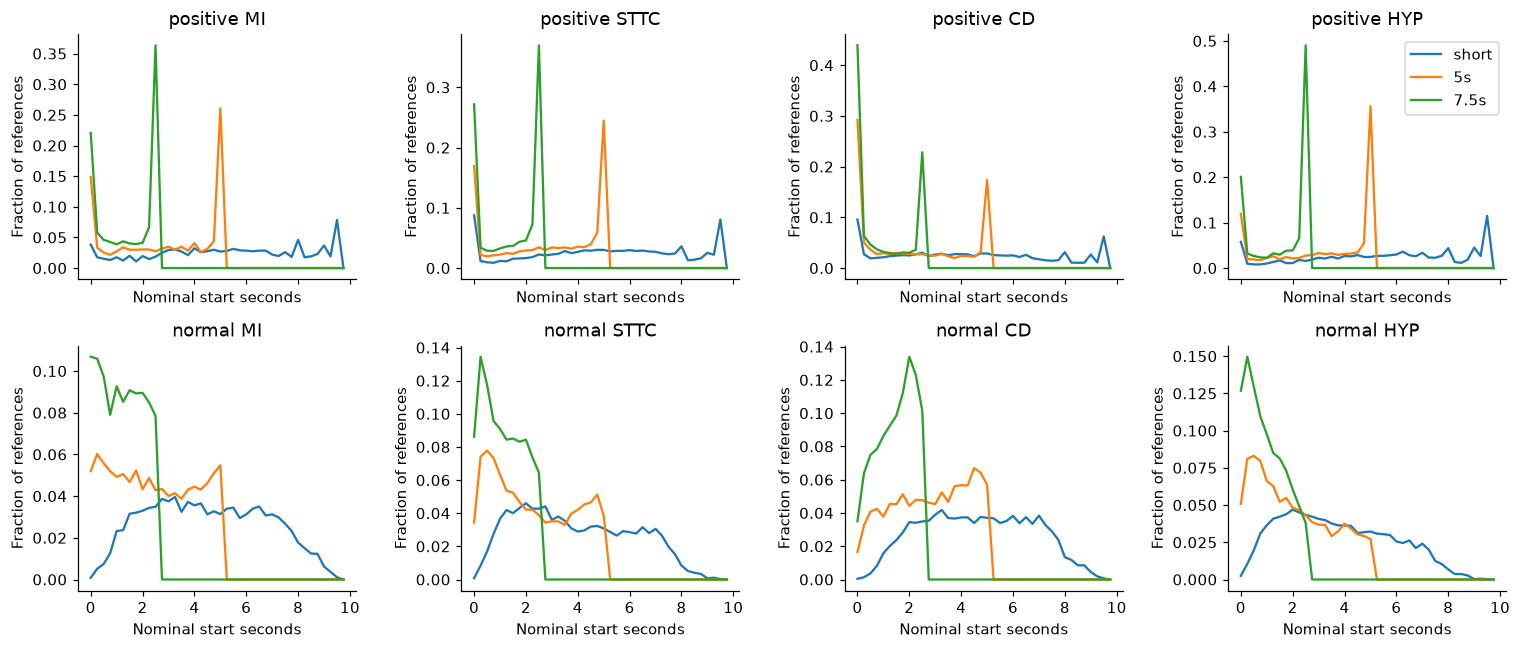

chapman_ningbo   cpsc  georgia  ptbxl
arm   key                                                 
short positive_MI             5.869  5.007    8.167  5.250
      positive_STTC           5.085  4.218    5.056  5.066
      positive_CD             4.409  3.766    4.411  4.219
      positive_HYP            5.363  5.680    5.742  5.505
      normal_MI               4.373  4.209    4.542  4.692
      normal_STTC             3.826  3.786    3.879  4.001
      normal_CD               4.532  4.657    4.629  4.723
      normal_HYP              3.664  3.456    3.758  3.764
5s    positive_MI             3.123  2.698    4.000  2.847
      positive_STTC           2.932  2.514    2.805  2.844
      positive_CD             2.128  1.596    2.152  2.166
      positive_HYP            3.265  2.961    3.330  3.207
      normal_MI               2.345  2.114    2.393  2.518
      normal_STTC             2.230  2.057    2.240  2.322
      normal_CD               2.786  2.657    2.766  2.817
      normal_HYP              1.976  1.688    1.927  2.097
7.5s  positive_MI             1.662  1.338    2.500  1.430
      positive_STTC           1.472  1.164    1.378  1.394
      positive_CD             0.951  0.621    0.993  0.995
      positive_HYP            1.712  1.500    1.695  1.604
      normal_MI               1.153  1.086    1.186  1.244
      normal_STTC             1.100  1.062    1.150  1.161
      normal_CD               1.430  1.477    1.490  1.476
      normal_HYP              0.935  0.883    0.944  1.007

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for row, kind in enumerate(['positive', 'normal']):
    for col, group in enumerate(groups):
        ax = axes[row, col]
        for arm in ['short', '5s', '7.5s']:
            v = r['geometry'][arm]['groups'][kind + '_' + group]
            ax.plot(np.arange(40)/4, np.asarray(v['start_counts'])/v['records'], label=arm)
        ax.set(title=kind + ' ' + group, xlabel='Nominal start seconds', ylabel='Fraction of references')
axes[0, -1].legend()
plt.tight_layout()
plt.show()
source_starts = pd.DataFrame([{'arm': a, 'key': g, **v.get('source_mean_start_seconds', {})}
    for a, details in r['geometry'].items() if a != 'whole'
    for g, v in details['groups'].items()]).set_index(['arm', 'key'])
display(source_starts.loc[['short', '5s', '7.5s']].round(3))

### 9. Inspecting actual training waveforms

Four roles per group and the normal pool were fixed before selection: nearest to the whole key
within each of the two largest source families; least similar to the whole key; largest vector
change after short-section selection. Repeated ECGs are loaded once, but all twenty review roles
are retained. The normal change example uses the MI-specific normal selection.

Each lead uses its own vertical axis limits; compare the numeric mV ticks rather than apparent
trace heights across leads. These are scientific plots, not a calibrated ECG-paper layout.

Each waveform is checked against raw-file and canonical-signal hashes by the existing training
loader. The private atlas plots all twelve leads in mV with nominal short, five- and 7.5-second
selection bars. Labels are existing annotations, not a new reading. Finite/flat-lead observations
are descriptive quality checks and cannot certify clinical validity.

Local artifacts:
- `outputs/reference_ecg_audit_20261106/ReferenceECGAtlas.pdf`
- `outputs/reference_ecg_audit_20261106/ReferenceWaveforms.ipynb`

Individual waveform images and original record mappings are deliberately kept out of the aggregate
Git notebook. These can be reviewed locally with the cardiologist without changing the frozen labels.

In [34]:
display(pd.Series(r['waveform_review'], name='executed waveform review').to_frame())
checks = 0
for group, values in r['composition'].items():
    assert sum(values['sources'].values()) == values['records']
    assert sum(values['families'].values()) == values['records']
    assert values['known_identity_records'] + values['unknown_identity_records'] == values['records']
    checks += 3
for arm, details in r['geometry'].items():
    assert details['key_max_error'] <= 1e-12
    checks += 1
    for key, values in details['groups'].items():
        assert sum(values['top50_sources'].values()) == 50
        checks += 1
        if 'start_counts' in values:
            assert sum(values['start_counts']) == values['records']
            assert sum(values['length_counts'].values()) == values['records']
            checks += 2
assert np.array_equal(co, co.T)
checks += 1
print('Aggregate consistency checks passed:', checks)
print('Clinical adjudication performed:', r['clinical_review_performed'])

,executed waveform review
panels,20
unique_waveforms,20
all_finite,True
panels_with_flat_leads,0


Aggregate consistency checks passed: 150
Clinical adjudication performed: False


### Observed patterns in these references

The MI support pool is 79.7% PTB-XL, and 45 of its 50 nearest whole-key references are PTB-XL.
The STTC pool is 63.7% Chapman/Ningbo, with 47 of its 50 nearest references from that family.
Removing these families rotates the respective whole keys by about 46 and 61 degrees.
These geometry shifts combine sample-share, acquisition and annotation differences; they do not
isolate a hospital artifact or prove that source balancing would improve prediction.

Only 812 of 2,041 MI references and 593 of 2,376 HYP references carry their group exclusively.
Thus about 60% of MI and 75% of HYP references also contribute other abnormal annotations.
The keys summarize mixtures of findings, not isolated examples of one disease.

Short selection increases positive-reference coherence but rotates their keys by roughly 39–48
degrees. Five- and 7.5-second keys rotate less. Together with KEY-01/02's measured performance,
this shows that a more tightly aligned training reference bank can transfer worse. The cause is
not established by these descriptive comparisons.

Among identified PTB patients, record repetition accounts for 469 extra records across the full
cohort. Equal-known-patient weighting rotates whole keys by about 0.5–2.1 degrees. That limited
check is much smaller than dominant-source removal, but 18,172 records lack patient identity.
It cannot rule out repeated-patient effects in those sources.

All twenty sampled waveforms were finite and had no flat lead. That does not establish freedom
from noise or drift. In the local atlas, Reference 16 shows a pronounced slow V4 level shift and
its short selected window covers the initial half-second. Its existing review-flag field is empty.
This visual observation is post hoc, warrants quality review, and does not prove why its key moved.
It is not a new diagnosis or an automatically applied exclusion.

### Interpretation and reproduction

This is a descriptive audit of fixed reference averages. Geometry shifts and source concentration
can motivate follow-up hypotheses but do not establish why a particular prediction was wrong.
No reference is removed, relabeled or reweighted in the deployed classifier. Recommendations and
observed findings are recorded in the separate results report.

Run the frozen audit with `python -m scripts.experiments.run_reference_ecg_audit` in a fresh output
directory with original local caches and permitted raw training data. Rebuild the notebooks with
`python -m scripts.reports.build_reference_audit_notebooks`. The prior KEY-01/02 conclusions remain.

OpenAI Codex assisted with implementation, analysis and prose. Computations and waveform rendering
were local; no external ECG inference API was used. The waveform panels have not been clinically
adjudicated, and project authors are responsible for reviewing their interpretation.

<a id="classifiers"></a>
## IV. Matched multiclass and independent-label classification — KEY-04

The previous studies show how reference averages behave. This comparison asks whether a
learned classifier makes better use of the **same normalized xECG features and same training
labels**. No encoder, new data source or clinical definition is added.

An ECG can have several findings. To provide a genuine multiclass method without throwing away
co-occurrence, multinomial logistic regression predicts sixteen existing annotation combinations.
The state code is `MI + 2*STTC + 4*CD + 8*HYP`. Zero is the normal annotation proxy. These are
sixteen combinations of four groups, not sixteen diseases. Each combination is mutually exclusive
as a state, while its four component annotations can overlap.

For comparison with keys, sum each predicted state's probability into the groups it contains.
For example, probability assigned to MI+STTC contributes to both MI and STTC marginal scores.
A second family uses four independent binary logistic regressions. The common primary endpoint
is the four-group macro one-versus-rest AUROC, not exact-state accuracy.


In [35]:
from sklearn.metrics import roc_curve, precision_recall_curve

K4 = json.loads((ROOT / 'reports/condition-classifiers-2026-11-06/aggregate.json').read_text())
NC = json.loads((ROOT / 'reports/condition-classifiers-2026-11-06/negative-control.json').read_text())
AUDIT4 = json.loads((ROOT / 'reports/condition-classifiers-2026-11-06/verification.json').read_text())
KP = np.load(ROOT / 'outputs/condition_classifiers_20261106/predictions.npz', allow_pickle=False)
negative_path = ROOT / 'outputs/condition_classifiers_negative_control_20261106/artifacts.npz'
NP = np.load(negative_path, allow_pickle=False)
assert K4['status'] == NC['status'] == 'completed'
assert AUDIT4['status'] == 'passed'
assert np.array_equal(KP['flags'], NP['flags'])
print('KEY-04 source:', K4['git_commit'])
print('Independent arithmetic verification:', AUDIT4['status'])
display(pd.DataFrame(K4['qualification']['folds'])[['fold', 'records', 'groups']])


KEY-04 source: aec367c40a6f720ce899bd22a1f55cee45f58ba8
Independent arithmetic verification: passed


,fold,records,groups
0,0,8340,8177
1,1,8314,8177
2,2,8346,8177


### Training-only model selection

Both families use the same three folds, grouped by known patient identity. Unknown-patient records
retain distinct record groups; this cannot establish patient independence in those sources.
Each fold refits its own StandardScaler on fitting rows, then normalizes vectors. Neither SPH
features nor labels fit a scaler or select regularization.

C is selected separately from 0.1, 1 and 10 using mean fold macro AUROC; ties choose smaller C.
All fits use L2 logistic regression, lbfgs, tolerance 1e-8 and at most 5,000 iterations. Nonconverged
fits stop the study. The table includes every registered candidate, not just the selected one.
If the best C is at the grid boundary, this is a bounded comparison, not a claim of global optimum.


family,independent_logistic,joint_logistic
C,,
0.100000,0.899718,0.894920
1.000000,0.918938,0.918460
10.000000,0.925873,0.926618


Training-selected C: {'joint_logistic': 10.0, 'independent_logistic': 10.0}


,family,C,fold,macro AUROC,fit seconds
0,joint_logistic,1.0,0,0.918543,7.774505
1,independent_logistic,1.0,0,0.918834,3.112514
2,joint_logistic,0.1,0,0.891637,2.541261
3,joint_logistic,0.1,1,0.895087,2.567185
4,joint_logistic,0.1,2,0.898037,2.579000
5,joint_logistic,1.0,1,0.918014,6.581496
6,joint_logistic,1.0,2,0.918822,6.336012
7,joint_logistic,10.0,0,0.927553,17.139678
8,joint_logistic,10.0,1,0.926195,17.937860
9,joint_logistic,10.0,2,0.926107,17.080278


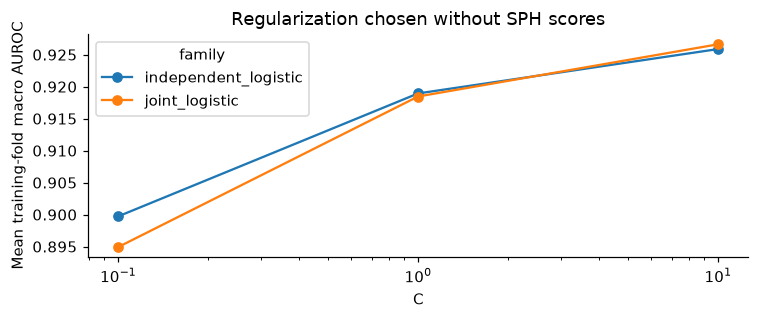

In [36]:
cv_table = pd.DataFrame(K4['cross_validation']['selection_table'])
display(cv_table.pivot(index='C', columns='family', values='mean_fold_macro_auroc').style.format('{:.6f}'))
print('Training-selected C:', K4['cross_validation']['chosen_C'])
fold_table = pd.DataFrame([{'family': row['family'], 'C': row['C'], 'fold': row['fold'],
                           'macro AUROC': row['metrics']['macro_auroc'],
                           'fit seconds': row['fit_seconds']}
                          for row in K4['cross_validation']['fold_metrics']])
display(fold_table)
cv_table.pivot(index='C', columns='family', values='mean_fold_macro_auroc').plot(
    marker='o', figsize=(7, 3), logx=True)
plt.ylabel('Mean training-fold macro AUROC')
plt.title('Regularization chosen without SPH scores')
plt.tight_layout()
plt.show()


### A control for negative-reference composition

The original positive-minus-normal keys use only normals as negative references. The classifiers
also learn from other abnormal combinations. A secondary control was registered before the new
SPH predictions: retain the same positive keys, but construct each negative key from **all training
ECGs lacking that group**. A co-occurring positive never enters its own group's negative pool.

This control isolates negative-key composition. It does not equalize classifier capacity or turn
prototype scores into calibrated probabilities. Its interval is exploratory, and it cannot replace
the original primary comparison after observing results.


In [37]:
comparison = pd.DataFrame({name: {'macro AUROC': values['macro_auroc'],
                                  'macro AP': values['macro_average_precision']}
                           for name, values in K4['metrics'].items()}).T
comparison.loc['all_other_negative_keys'] = [NC['metrics']['macro_auroc'],
                                            NC['metrics']['macro_average_precision']]
display(comparison.style.format('{:.6f}'))
display(pd.DataFrame({'primary joint minus whole': K4['primary'],
                     'exploratory independent minus whole': K4['exploratory_independent_contrast'],
                     'exploratory negative control minus whole': NC['versus_whole']}).T)
print('Registered ranking decision:', K4['decision'])
print('Clinical pipeline promoted:', K4['decision']['clinical_pipeline_promoted'])


,macro AUROC,macro AP
whole,0.896102,0.417818
joint_logistic,0.957750,0.661003
independent_logistic,0.960845,0.668734
all_other_negative_keys,0.910448,0.466428


,difference,ci_low,ci_high,draws,skipped_draws,seed
primary joint minus whole,0.061648,0.053031,0.070926,2000.0,0.0,20261103.0
exploratory independent minus whole,0.064743,0.056628,0.073633,2000.0,0.0,20261103.0
exploratory negative control minus whole,0.014346,0.012269,0.016535,2000.0,0.0,20261103.0


Registered ranking decision: {'gain_at_least_0.01': True, 'lower_95_above_zero': True, 'ranking_improvement': True, 'clinical_pipeline_promoted': False}
Clinical pipeline promoted: False


### Per-group ranking and precision–recall

All evaluated records contribute to each one-versus-rest task, including other abnormalities.
Average precision depends on prevalence; comparing all methods on the identical evaluation rows
keeps that prevalence fixed. Rare MI/HYP groups should not be judged by AUROC alone.
Probabilities come from the source-trained models and have not been clinically calibrated at SPH.


model,all_other_negative_keys,independent_logistic,joint_logistic,whole
group,,,,
CD,0.8716,0.9255,0.9164,0.8409
HYP,0.9050,0.9764,0.9771,0.8956
MI,0.9305,0.9824,0.9776,0.9245
STTC,0.9348,0.9590,0.9599,0.9234


model,all_other_negative_keys,independent_logistic,joint_logistic,whole
group,,,,
CD,0.5819,0.7620,0.7520,0.4561
HYP,0.2203,0.3980,0.3886,0.2047
MI,0.2326,0.6122,0.5979,0.2149
STTC,0.8309,0.9027,0.9056,0.7956


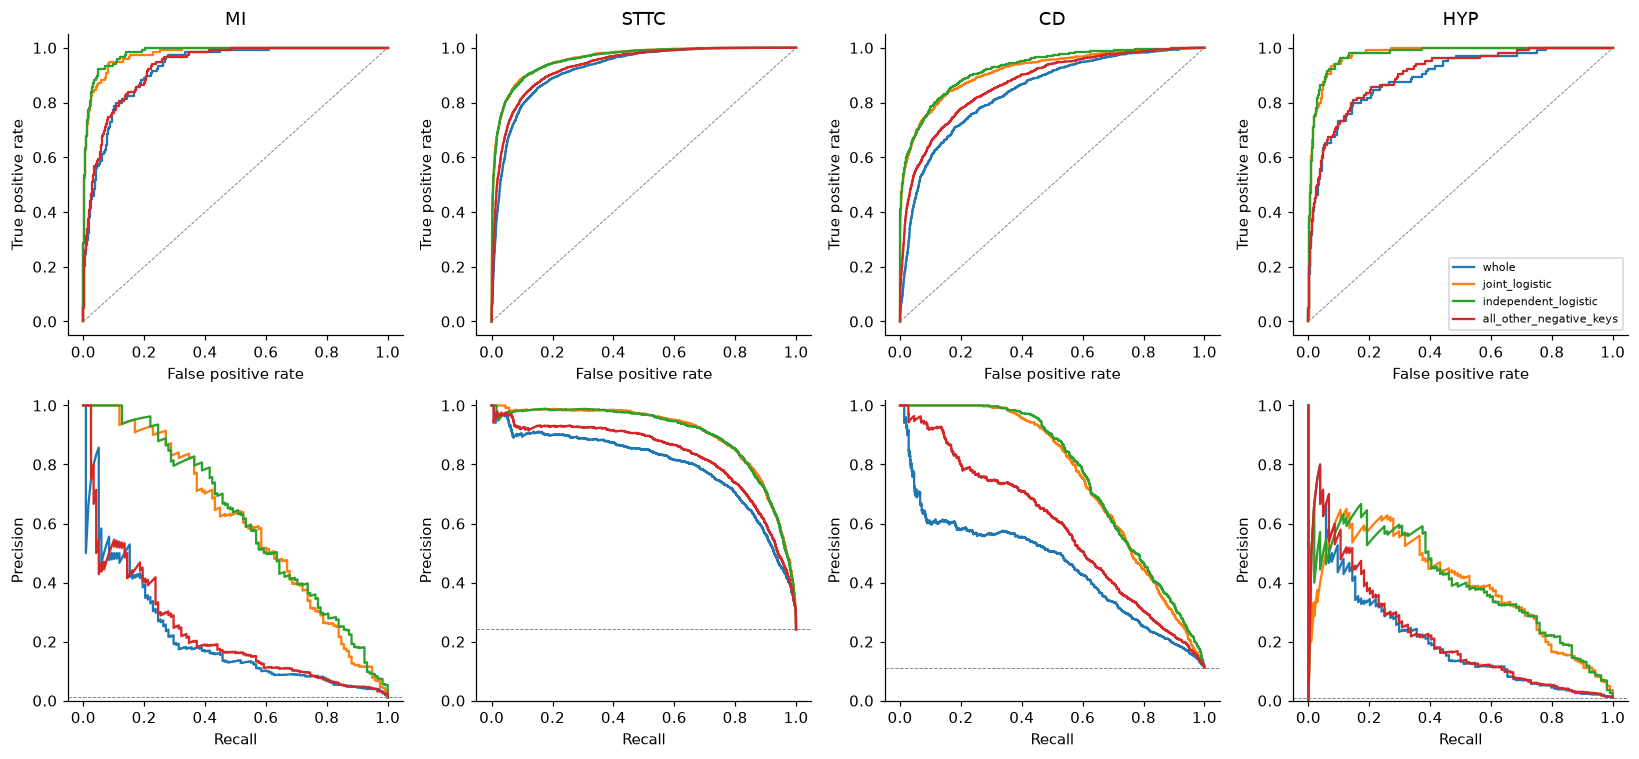

In [38]:
model_scores = {name: KP['score_' + name] for name in K4['metrics']}
model_scores['all_other_negative_keys'] = NP['scores']
per_group = pd.DataFrame([{'model': name, 'group': g, **values['groups'][g]}
                          for name, values in {**K4['metrics'],
                                               'all_other_negative_keys': NC['metrics']}.items()
                          for g in ['MI', 'STTC', 'CD', 'HYP']])
display(per_group.pivot(index='group', columns='model', values='auroc').style.format('{:.4f}'))
display(per_group.pivot(index='group', columns='model', values='average_precision').style.format('{:.4f}'))
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for c, g in enumerate(['MI', 'STTC', 'CD', 'HYP']):
    y = KP['flags'][:, c]
    for name, values in model_scores.items():
        fpr, tpr, _ = roc_curve(y, values[:, c])
        precision, recall, _ = precision_recall_curve(y, values[:, c])
        axes[0, c].plot(fpr, tpr, label=name)
        axes[1, c].plot(recall, precision, label=name)
    axes[0, c].plot([0, 1], [0, 1], '--', color='gray', linewidth=.6)
    axes[1, c].axhline(y.mean(), linestyle='--', color='gray', linewidth=.6)
    axes[0, c].set(title=g, xlabel='False positive rate', ylabel='True positive rate')
    axes[1, c].set(xlabel='Recall', ylabel='Precision', ylim=(0, 1.02))
axes[0, -1].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()


### Genuine multiclass performance and rare combinations

The joint model chooses one of sixteen annotation states by probability argmax. This is a
classification endpoint, not a calibrated referral rule. Keys do not define joint-state probabilities,
so no artificial multiclass accuracy or log loss is assigned to them.

Exact-state accuracy can be dominated by common combinations. Supported-state macro recall and
the full confusion matrix expose that. Recall is undefined where a state has no evaluation examples;
precision is undefined if no record was predicted into that state. These entries remain missing.
The dummy always chooses the most common training state, never the most common SPH state.


,code,annotations,training ECGs,SPH ECGs,predicted ECGs,precision,recall,F1
0,0,normal_proxy,7393,6850,6862,0.908190,0.909781,0.908985
1,1,MI,812,40,65,0.200000,0.325000,0.247619
2,2,STTC,8578,2224,2581,0.728787,0.845773,0.782934
3,3,MI+STTC,375,55,16,0.625000,0.181818,0.281690
4,4,CD,3084,980,742,0.739892,0.560204,0.637631
5,5,MI+CD,449,11,4,0.250000,0.090909,0.133333
6,6,STTC+CD,1813,159,93,0.473118,0.276730,0.349206
7,7,MI+STTC+CD,120,11,0,NaN,0.000000,0.000000
8,8,HYP,593,29,11,0.272727,0.103448,0.150000
9,9,MI+HYP,62,0,0,NaN,NaN,NaN


,multiclass result
exact_state_accuracy,0.839467
macro_recall_supported_states,0.319691
top_two_accuracy,0.957447
log_loss,0.477496
training_majority_state,2.000000
training_majority_accuracy,0.213149


predicted state,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
true state,,,,,,,,,,,,,,,,
0,6232,20,456,0,136,0,3,0,2,0,1,0,0,0,0,0
1,6,13,17,1,2,0,1,0,0,0,0,0,0,0,0,0
2,275,9,1881,3,17,1,15,0,4,0,19,0,0,0,0,0
3,0,17,23,10,0,0,2,0,0,0,1,2,0,0,0,0
4,335,1,74,0,549,0,19,0,1,0,1,0,0,0,0,0
5,1,2,0,0,4,1,2,0,0,0,0,0,1,0,0,0
6,5,1,74,0,31,1,44,0,0,0,1,0,0,0,2,0
7,0,1,2,2,1,1,4,0,0,0,0,0,0,0,0,0
8,8,0,13,0,0,0,1,0,3,0,4,0,0,0,0,0


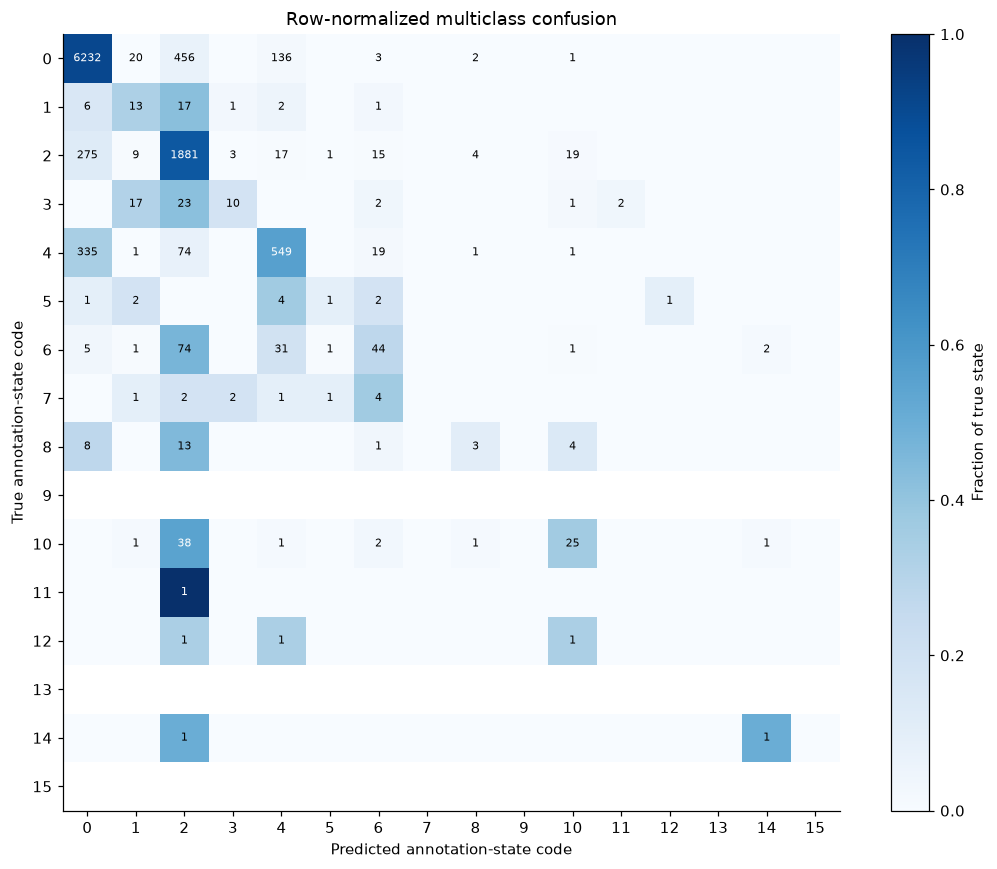

In [39]:
multi = K4['multiclass']
state_counts = pd.DataFrame({'code': range(16), 'annotations': multi['state_names'],
                            'training ECGs': K4['qualification']['training_state_counts'],
                            'SPH ECGs': multi['support'], 'predicted ECGs': multi['predicted_count'],
                            'precision': multi['precision'], 'recall': multi['recall'], 'F1': multi['f1']})
display(state_counts)
display(pd.Series({k: multi[k] for k in ['exact_state_accuracy', 'macro_recall_supported_states',
    'top_two_accuracy', 'log_loss', 'training_majority_state', 'training_majority_accuracy']},
    name='multiclass result').to_frame())
matrix = np.asarray(multi['confusion'])
display(pd.DataFrame(matrix, index=pd.Index(range(16), name='true state'),
                     columns=pd.Index(range(16), name='predicted state')))
row_totals = matrix.sum(axis=1)
normalized = np.divide(matrix, row_totals[:, None], out=np.full(matrix.shape, np.nan),
                       where=row_totals[:, None] != 0)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(normalized, vmin=0, vmax=1, cmap='Blues')
ax.set(xticks=range(16), yticks=range(16), xlabel='Predicted annotation-state code',
       ylabel='True annotation-state code', title='Row-normalized multiclass confusion')
for i in range(16):
    for j in range(16):
        if matrix[i, j]:
            ax.text(j, i, str(matrix[i,j]), ha='center', va='center', fontsize=7,
                    color='white' if normalized[i,j] > .55 else 'black')
fig.colorbar(im, ax=ax, label='Fraction of true state')
plt.tight_layout()
plt.show()


### Error patterns and co-occurring findings

The next table ranks aggregate exact-state errors. It describes annotation-combination mistakes;
it is not a list of missed diseases or clinical referral decisions. The following subset comparison
uses exclusive or co-occurring positives against the same normal negative pool. Its denominators
are different from the primary all-other-negative task, so its numbers cannot replace that result.


In [40]:
errors = [{'true annotations': multi['state_names'][i],
           'predicted annotations': multi['state_names'][j], 'ECGs': int(matrix[i,j])}
          for i in range(16) for j in range(16) if i != j and matrix[i,j] > 0]
display(pd.DataFrame(errors).sort_values('ECGs', ascending=False).head(15))
subsets = pd.DataFrame([{'group': group, 'positive subset': subset, 'model': model,
                        'positive ECGs': values['positives'], 'normal ECGs': values['normals'], **point}
                       for group, parts in K4['error_subsets'].items()
                       for subset, values in parts.items()
                       for model, point in values['models'].items()])
display(subsets)


,true annotations,predicted annotations,ECGs
1,normal_proxy,STTC,456
24,CD,normal_proxy,335
11,STTC,normal_proxy,275
2,normal_proxy,CD,136
26,CD,STTC,74
37,STTC+CD,STTC,74
53,STTC+HYP,STTC,38
38,STTC+CD,CD,31
20,MI+STTC,STTC,23
0,normal_proxy,MI,20


,group,positive subset,model,positive ECGs,normal ECGs,auroc,average_precision
0,MI,exclusive,whole,40,6850,0.952777,0.332520
1,MI,exclusive,joint_logistic,40,6850,0.984697,0.513181
2,MI,exclusive,independent_logistic,40,6850,0.986923,0.591585
3,MI,cooccurring,whole,78,6850,0.984765,0.668388
4,MI,cooccurring,joint_logistic,78,6850,0.984116,0.681657
5,MI,cooccurring,independent_logistic,78,6850,0.992456,0.808496
6,STTC,exclusive,whole,2224,6850,0.944044,0.884084
7,STTC,exclusive,joint_logistic,2224,6850,0.964229,0.922587
8,STTC,exclusive,independent_logistic,2224,6850,0.963332,0.922063
9,STTC,cooccurring,whole,297,6850,0.980626,0.875464


### Does the advantage survive different reference samples?

Ten source-family-stratified reference bootstraps were registered in advance. Known patients are
resampled as whole groups; unknown identities remain record groups. Each draw refits its scaler,
prototypes and both classifiers from the same sampled rows, using C selected before SPH scoring.
Every draw is retained. The ranges below are **not confidence intervals** and the draws are not
ten independent hospitals. They assess reference-sampling sensitivity conditional on the fixed
encoder, selected C and the same SPH evaluation set.


,seed,model,training rows,unique training groups,AUROC difference,AP difference
0,20261206,joint_logistic,25012,15503,0.061059,0.229512
1,20261206,independent_logistic,25012,15503,0.064321,0.235379
2,20261207,joint_logistic,24980,15526,0.061547,0.240666
3,20261207,independent_logistic,24980,15526,0.065015,0.252127
4,20261208,joint_logistic,25011,15552,0.058850,0.230857
5,20261208,independent_logistic,25011,15552,0.061915,0.236955
6,20261209,joint_logistic,24960,15467,0.057517,0.225649
7,20261209,independent_logistic,24960,15467,0.058883,0.231249
8,20261210,joint_logistic,24991,15518,0.056604,0.235226
9,20261210,independent_logistic,24991,15518,0.060046,0.239020


AUROC difference                     AP difference  \
                                  min    median       max           min   
model                                                                     
independent_logistic         0.058883  0.061792  0.065015      0.220578   
joint_logistic               0.053701  0.057941  0.061547      0.213144   

                                          
                        median       max  
model                                     
independent_logistic  0.236727  0.252127  
joint_logistic        0.227580  0.240666

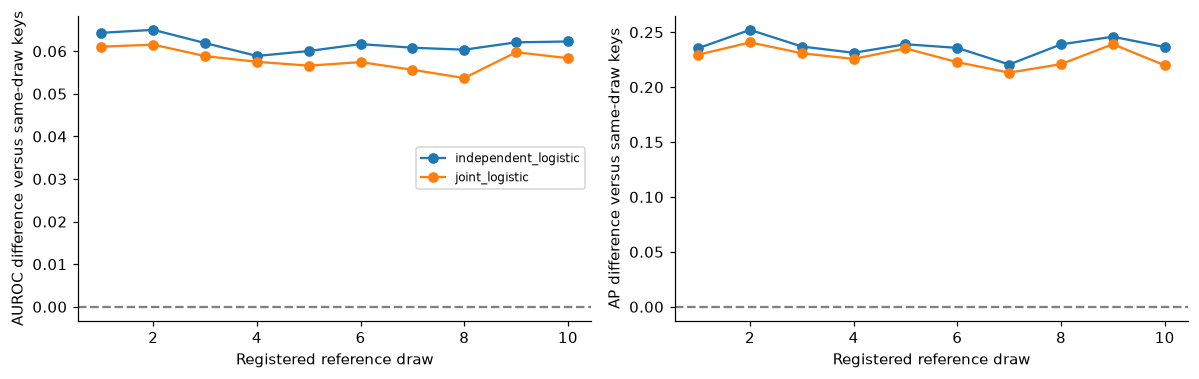

In [41]:
draw_rows = []
for draw in K4['reference_sensitivity']:
    for model, contrast in draw['differences'].items():
        draw_rows.append({'seed': draw['seed'], 'model': model,
                          'training rows': draw['training_rows'],
                          'unique training groups': draw['unique_training_groups'],
                          'AUROC difference': contrast['macro_auroc'],
                          'AP difference': contrast['macro_average_precision']})
draws = pd.DataFrame(draw_rows)
display(draws)
display(draws.groupby('model')[['AUROC difference', 'AP difference']].agg(['min', 'median', 'max']))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric in zip(axes, ['AUROC difference', 'AP difference']):
    for model, part in draws.groupby('model'):
        ax.plot(range(1, len(part)+1), part[metric], marker='o', label=model)
    ax.axhline(0, color='gray', linestyle='--')
    ax.set(xlabel='Registered reference draw', ylabel=metric + ' versus same-draw keys')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


<a id="interpretation"></a>
## V. What this deeper comparison does and does not establish

- All models use the same permitted source pool, but they use its labels differently. The extra
  negative-reference control isolates one such difference; it does not equalize capacity.
- Training-only model selection keeps SPH out of hyperparameter fitting. SPH has still been read
  repeatedly across this research sequence, so these results remain external development evidence.
- Paired patient intervals quantify evaluation sampling conditional on fitted models. The ten
  reference resamples assess another sensitivity, but do not include reselecting C, new encoders,
  unknown repeated patients or independently acquired hospitals.
- High four-group AUROC can coexist with poor exact recognition of rare combinations. Review
  per-group AP, per-state support and confusion before interpreting a single summary.
- A source-removed key rotation combines sample share, acquisition and label differences. It is
  not a causal estimate of hospital/device bias. Likewise, the single cyclic-key control from
  KEY-01 is a diagnostic example, not a permutation significance test.
- The twenty waveform examples were selected for geometry review, not sampled to estimate
  population signal quality. Finite samples and no flat leads do not certify absence of artifacts.
- Our region analyses pool contextual xECG tokens. They do not implement SAM segmentation,
  lead-preserving JEPA/CroPA, physiological localization or a cardiologist's reasoning process.
- The four memberships are annotation proxies; this work has not established diagnosis,
  unseen-condition recognition, student screening performance or a final clinical operating point.

The software and arithmetic audit below checks reproducibility. Passing it does not validate the
clinical target or remove these scientific limitations. Project recommendations remain in the
separate results report.


In [42]:
display(pd.Series(AUDIT4, name='saved-output audit').to_frame())
assert AUDIT4['new_fits'] == 0
assert AUDIT4['primary_interval_exact']
assert AUDIT4['known_patient_fold_separation_verified']
assert AUDIT4['bootstrap_group_multiplicities_exact']
print('Registered ranking improvement:', K4['decision']['ranking_improvement'])
print('No clinical pipeline promotion:', not K4['decision']['clinical_pipeline_promoted'])


,saved-output audit
status,passed
metric_and_denominator_fields,1310
cv_packages_verified,18
reference_draws_verified,10
max_parameter_prediction_error,0.0
primary_interval_exact,True
known_patient_fold_separation_verified,True
bootstrap_group_multiplicities_exact,True
result_sha256,40e8fdb8809b6e727680dac193d00c380d04ec0e51630b...
audit_source_sha256,5d97807bd59d9139f817de64999d419c29c0bc8a37544b...


Registered ranking improvement: True
No clinical pipeline promotion: True


### Reproduction and AI assistance

Scientific execution: `python -m scripts.experiments.run_key_classifiers`, followed by the
registered `run_key_negative_control` and `scripts.reports.audit_key_classifiers`. Original
local cache identities and a fresh output directory are required; scientific runs refuse overwrite.
Build this consolidated notebook with `python -m scripts.reports.build_jr_condition_study`.

The earlier notebooks and their scientific receipts remain intact. This notebook re-executes their
aggregate analysis cells and adds KEY-04; it does not repeat encoder extraction or display private
individual-waveform images. The separate local atlas remains available for review.

OpenAI Codex assisted with the prospective designs, code, plots and explanatory text. Numerical
results were executed locally. The project authors remain responsible for reviewing the methods,
interpretations and clinical scope. No external model inference was used on ECG data here.
